# NB02 — Complete evaluation for the paper
**Settings:** GPU T4 x2 (one GPU is used) · Internet On.
**Input:** the output of the training notebook (Add Input → Your Work → the NB01 notebook that finished all 24 runs).
It contains `prep/` (data, masks, split) and `runs/` (24 models). Run with **Save & Run All**. Everything is written to
`/kaggle/working/eval` (tables as CSV + LaTeX, figures as PNG/PDF, `summary.json`).

In [1]:
%%writefile artproto.py
"""
artproto.py -- shared library for the paper
"Artifact-aware prototype learning for skin-lesion classification".

Everything (data caching, lesion/artifact masks, models, losses, training,
push, evaluation, counterfactuals) lives here so that every notebook uses
exactly the same code.
"""
import os, re, json, glob, math, time, random, copy, traceback
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F

IMG = 256          # cached resolution (square, as in the original project)
OUT = 224          # network input resolution
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

# bit layout of the uint8 mask array
BIT_L, BIT_DC, BIT_TS, BIT_SP, BIT_INK = 1, 2, 4, 8, 16
BIT_ART = BIT_DC | BIT_TS | BIT_SP | BIT_INK
ART_BITS = {"DC": BIT_DC, "TS": BIT_TS, "SP": BIT_SP, "INK": BIT_INK}
ART_LONG = {"DC": "dark corner / vignette", "TS": "thin dark structures (hair, ruler ticks)",
            "SP": "specular highlights / gel bubbles", "INK": "ink markings / coloured patches"}
DETECTOR_VERSION = 2
# image-level presence thresholds (fraction of image area)
ART_MIN_FRAC = {"DC": 0.01, "TS": 0.003, "SP": 0.0005, "INK": 0.001}


# ----------------------------------------------------------------------------- utils
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def walk_files(root="/kaggle/input"):
    """Recursive file list. followlinks=True is REQUIRED: recent Kaggle images mount
    datasets as symlinks under /kaggle/input, which os.walk skips by default."""
    out, seen = [], set()
    for r, ds, fs in os.walk(root, followlinks=True):
        real = os.path.realpath(r)
        if real in seen:                      # guard against symlink cycles
            ds[:] = []; continue
        seen.add(real)
        for f in fs:
            out.append(os.path.join(r, f).replace(os.sep, '/'))
    return out


def load_rgb_resized(path, size=IMG):
    from PIL import Image
    im = Image.open(path)
    try:
        im.draft("RGB", (size * 2, size * 2))      # fast JPEG decoding at reduced scale
    except Exception:
        pass
    a = np.asarray(im.convert("RGB"))
    return cv2.resize(a, (size, size), interpolation=cv2.INTER_AREA)


def load_mask_resized(path, size=IMG):
    from PIL import Image
    m = np.asarray(Image.open(path).convert("L"))
    m = cv2.resize(m, (size, size), interpolation=cv2.INTER_AREA)
    return (m >= 128).astype(np.uint8)


def phash64(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    g = cv2.resize(g, (32, 32), interpolation=cv2.INTER_AREA)
    d = cv2.dct(g)[:8, :8].flatten()
    return d > np.median(d[1:])


def thumbs(img):
    """z-normalised 32x32 grey thumbnails of the full image and of the central 50% crop
    (used to VERIFY pHash duplicate candidates; the centre crop ignores vignettes)."""
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    out = []
    for a in (g, g[64:192, 64:192]):
        t = cv2.resize(a, (32, 32), interpolation=cv2.INTER_AREA).flatten()
        t = (t - t.mean()) / (t.std() + 1e-6) / np.sqrt(t.size)
        out.append(t.astype(np.float16))
    return out[0], out[1]


def hamming_pairs(bitsA, bitsB=None, thr=6, device="cuda", chunk=2048):
    """Return (i, j, ham) with ham <= thr. If bitsB is None: pairs inside A with i<j."""
    dev = device if torch.cuda.is_available() else "cpu"
    dt = torch.float16 if dev != "cpu" else torch.float32
    A = torch.from_numpy(bitsA.astype(np.float32) * 2 - 1).to(dev, dt)
    B = A if bitsB is None else torch.from_numpy(bitsB.astype(np.float32) * 2 - 1).to(dev, dt)
    out = []
    for s in range(0, len(A), chunk):
        ham = (64 - (A[s:s + chunk] @ B.T).float()) / 2
        ii, jj = torch.nonzero(ham <= thr + 1e-3, as_tuple=True)
        h = ham[ii, jj]
        ii = ii + s
        if bitsB is None:
            keep = ii < jj
            ii, jj, h = ii[keep], jj[keep], h[keep]
        out.append(torch.stack([ii.float(), jj.float(), h], 1).cpu())
    o = torch.cat(out).numpy() if out else np.zeros((0, 3))
    return o[:, 0].astype(int), o[:, 1].astype(int), o[:, 2].astype(int)


class UnionFind:
    def __init__(self, n): self.p = np.arange(n)
    def find(self, a):
        while self.p[a] != a:
            self.p[a] = self.p[self.p[a]]; a = self.p[a]
        return a
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb: self.p[max(ra, rb)] = min(ra, rb)


# ----------------------------------------------------------------------------- masks
def postprocess_lesion(prob, thr=0.5, min_frac=0.005):
    m = (prob >= thr).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8)
    if n <= 1:
        return np.zeros_like(m), False
    j = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    m = (lab == j).astype(np.uint8)
    inv = 1 - m                                         # fill holes
    n2, lab2, _, _ = cv2.connectedComponentsWithStats(inv, 4)
    border = np.unique(np.concatenate([lab2[0], lab2[-1], lab2[:, 0], lab2[:, -1]]))
    holes = ~np.isin(lab2, border) & (inv > 0)
    m[holes] = 1
    return m, bool(m.mean() >= min_frac)


def otsu_lesion(img):
    """Classical fallback lesion segmentation (only used if no GT masks are available)."""
    b = cv2.GaussianBlur(img[..., 2], (11, 11), 0)
    _, m = cv2.threshold(b, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return postprocess_lesion(m.astype(np.float32))


def detect_artifacts(img, L):
    """Rule-based artifact masks on a 256x256 RGB uint8 image.
    L: uint8 lesion mask. Artifact pixels are never inside the (dilated) lesion.
    Returns uint8 bitfield (DC|TS|SP|INK)."""
    H, W = L.shape
    area = H * W
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    Hh, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    Ld = cv2.dilate(L.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))) > 0

    # (1) dark corners / vignette: dark regions connected to the image border
    dark = cv2.morphologyEx((V < 50).astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(dark, 8)
    border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
    # must be a large blob (area) and not a thin line touching the border (hair): mean thickness >= 8 px
    keep = [b for b in border if b != 0 and st[b, cv2.CC_STAT_AREA] >= 0.002 * area and
            st[b, cv2.CC_STAT_AREA] / max(np.hypot(st[b, cv2.CC_STAT_WIDTH], st[b, cv2.CC_STAT_HEIGHT]), 1) >= 8]
    dc = np.isin(lab, keep) & ~Ld

    # (2) thin dark structures (hair, ruler ticks/lines): black-hat + elongation filter
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (13, 13))
    bh = cv2.morphologyEx(cv2.GaussianBlur(gray, (3, 3), 0), cv2.MORPH_BLACKHAT, k)
    ts = (bh >= 18).astype(np.uint8)
    ts[cv2.dilate(dc.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0] = 0
    ts[:4, :] = 0; ts[-4:, :] = 0; ts[:, :4] = 0; ts[:, -4:] = 0     # v2: no frame-edge strips
    n, lab, st, _ = cv2.connectedComponentsWithStats(ts, 8)
    a = st[:, cv2.CC_STAT_AREA].astype(np.float64)
    diag = np.hypot(st[:, cv2.CC_STAT_WIDTH], st[:, cv2.CC_STAT_HEIGHT])
    good = (a >= 15) & (diag >= 15) & (a / np.maximum(diag, 1) <= 6.0)
    good[0] = False
    ts = good[lab] & ~Ld

    # (3) specular highlights / gel bubbles: small bright unsaturated blobs that are much brighter
    #     than their surround (v2: white top-hat keeps only bright peaks smaller than 11 px -> large
    #     whitish skin areas are rejected; bubble rims and glints are kept)
    tophat = cv2.morphologyEx(V, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)))
    sp = ((V >= 210) & (S <= 50) & (tophat >= 25)).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(sp, 8)
    a = st[:, cv2.CC_STAT_AREA]
    good = (a >= 3) & (a <= 0.01 * area)
    good[0] = False
    sp = (cv2.dilate(good[lab].astype(np.uint8), np.ones((3, 3), np.uint8)) > 0) & ~Ld

    # (4) ink markings / coloured patches: strongly saturated blue-cyan-violet regions outside the lesion
    #     (v2: hue 90-150 also covers blue/cyan stickers; S>=90 rejects bluish-tinted skin; pink skin
    #      (H>150) excluded; a 12-px band next to the vignette is excluded (chromatic fringe))
    ink = cv2.morphologyEx(((Hh >= 90) & (Hh <= 150) & (S >= 90) & (V >= 40) & (V <= 235)).astype(np.uint8),
                           cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(ink, 8)
    good = st[:, cv2.CC_STAT_AREA] >= 40
    good[0] = False
    ink = good[lab] & ~Ld & ~(cv2.dilate(dc.astype(np.uint8), np.ones((25, 25), np.uint8)) > 0)

    return (dc * BIT_DC | ts * BIT_TS | sp * BIT_SP | ink * BIT_INK).astype(np.uint8)


def artifact_flags(mask_bits):
    """image-level presence flags from a (256,256) bitfield."""
    return {k: float(((mask_bits & b) > 0).mean()) >= ART_MIN_FRAC[k] for k, b in ART_BITS.items()}


# ----------------------------------------------------------------------------- GPU augmentation
def gpu_augment(img_u8, msk_u8, mode, out=OUT, gen=None):
    """img_u8 (B,256,256,3) uint8, msk_u8 (B,256,256) uint8 (on device).
    mode: 'eval' | 'std' | 'robust'. Image and masks receive the SAME geometric transform.
    Returns normalized image (B,3,out,out), lesion mask, artifact mask (B,1,out,out) in [0,1]."""
    dev = img_u8.device
    B = img_u8.shape[0]
    x = img_u8.permute(0, 3, 1, 2).float() / 255.0
    m = msk_u8.long()
    mL = ((m & BIT_L) > 0).float()[:, None]
    mA = ((m & BIT_ART) > 0).float()[:, None]
    R = lambda *s: torch.rand(*s, device=dev, generator=gen)
    theta = torch.zeros(B, 2, 3, device=dev)
    if mode == "eval":
        theta[:, 0, 0] = 1; theta[:, 1, 1] = 1
    elif mode == "std":       # Resize(256) + RandomCrop(224) + HFlip
        s = out / IMG
        fx = torch.where(R(B) < 0.5, -1.0, 1.0)
        theta[:, 0, 0] = s * fx; theta[:, 1, 1] = s
        theta[:, 0, 2] = (R(B) * 2 - 1) * (1 - s); theta[:, 1, 2] = (R(B) * 2 - 1) * (1 - s)
    elif mode == "robust":    # RandomResizedCrop(scale .4-1, ratio 3/4-4/3) + H/V flips (+ colour jitter)
        area = 0.4 + 0.6 * R(B)
        logr = math.log(3 / 4) + (math.log(4 / 3) - math.log(3 / 4)) * R(B)
        r = torch.exp(logr)
        sx = torch.sqrt(area * r).clamp(max=1.0); sy = torch.sqrt(area / r).clamp(max=1.0)
        fx = torch.where(R(B) < 0.5, -1.0, 1.0); fy = torch.where(R(B) < 0.5, -1.0, 1.0)
        theta[:, 0, 0] = sx * fx; theta[:, 1, 1] = sy * fy
        theta[:, 0, 2] = (R(B) * 2 - 1) * (1 - sx); theta[:, 1, 2] = (R(B) * 2 - 1) * (1 - sy)
    else:
        raise ValueError(mode)
    grid = F.affine_grid(theta, (B, 3, out, out), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)
    mm = F.grid_sample(torch.cat([mL, mA], 1), grid, mode="bilinear", padding_mode="border", align_corners=False)
    mL, mA = mm[:, :1], mm[:, 1:]
    if mode == "robust":      # ColorJitter(brightness=.2, contrast=.2, saturation=.2)
        b = (0.8 + 0.4 * R(B)).view(B, 1, 1, 1)
        x = (x * b).clamp(0, 1)
        c = (0.8 + 0.4 * R(B)).view(B, 1, 1, 1)
        g = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).mean((1, 2)).view(B, 1, 1, 1)
        x = ((x - g) * c + g).clamp(0, 1)
        s = (0.8 + 0.4 * R(B)).view(B, 1, 1, 1)
        gy = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2])[:, None]
        x = (gy + (x - gy) * s).clamp(0, 1)
    mean = torch.tensor(MEAN, device=dev).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=dev).view(1, 3, 1, 1)
    return (x - mean) / std, mL, mA


# ----------------------------------------------------------------------------- models
def densenet_features():
    from torchvision.models import densenet121, DenseNet121_Weights
    return densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1).features


class DenseCNN(nn.Module):
    """Black-box reference: DenseNet-121 + GAP + linear."""
    kind = "cnn"
    def __init__(self, n_classes=2, pretrained=True):
        super().__init__()
        self.features = densenet_features() if pretrained else _tiny_features()
        self.head = nn.Linear(1024, n_classes)
    def forward(self, x):
        f = F.relu(self.features(x))
        return {"logits": self.head(f.mean((2, 3))), "fmap": f}


class ProtoPNet(nn.Module):
    """ProtoPNet (Chen et al., NeurIPS 2019) with a DenseNet-121 backbone."""
    kind = "proto"
    def __init__(self, n_classes=2, ppc=10, D=128, pretrained=True):
        super().__init__()
        self.features = densenet_features() if pretrained else _tiny_features()
        self.add_on = nn.Sequential(nn.Conv2d(1024, D, 1), nn.ReLU(), nn.Conv2d(D, D, 1), nn.Sigmoid())
        P = n_classes * ppc
        self.prototypes = nn.Parameter(torch.rand(P, D, 1, 1))
        self.register_buffer("proto_class", torch.arange(P) // ppc)
        ident = F.one_hot(torch.arange(P) // ppc, n_classes).float().T          # (C,P)
        self.register_buffer("class_identity", ident)
        self.last = nn.Linear(P, n_classes, bias=False)
        with torch.no_grad():
            self.last.weight.copy_(1.0 * ident - 0.5 * (1 - ident))
        self.n_classes, self.P, self.D = n_classes, P, D

    def latent(self, x):
        f = F.relu(self.features(x))
        with torch.autocast("cuda", enabled=False):
            return self.add_on(f.float())

    def distances(self, z):
        x2 = (z ** 2).sum(1, keepdim=True)
        p2 = (self.prototypes ** 2).sum((1, 2, 3)).view(1, -1, 1, 1)
        xp = F.conv2d(z, self.prototypes)
        return F.relu(x2 + p2 - 2 * xp)

    def forward(self, x):
        z = self.latent(x)
        with torch.autocast("cuda", enabled=False):
            d = self.distances(z)
            sim = torch.log((d + 1) / (d + 1e-4))
            act = sim.amax((2, 3))
            logits = self.last(act)
        return {"logits": logits, "sim": sim, "dist": d, "min_d": d.amin((2, 3)), "act": act, "z": z}


def _tiny_features():  # CPU unit tests only
    return nn.Sequential(nn.Conv2d(3, 1024, 32, stride=32))


def build_model(cfg, pretrained=True):
    if cfg["model"] == "cnn":
        return DenseCNN(pretrained=pretrained)
    return ProtoPNet(ppc=cfg.get("ppc", 10), D=cfg.get("D", 128), pretrained=pretrained)


# ----------------------------------------------------------------------------- losses
def proto_base_losses(out, y, model, class_w):
    ce = F.cross_entropy(out["logits"], y, weight=class_w)
    md = out["min_d"]
    own = model.proto_class[None, :] == y[:, None]
    big = torch.finfo(md.dtype).max / 4
    clst = md.masked_fill(~own, big).amin(1).mean()
    sep = md.masked_fill(own, big).amin(1).mean()
    return ce, clst, sep


def artifact_lesion_losses(out, y, model, cL, cA, valid, tau=0.5):
    """Proposed losses.  sim: (B,P,h,w); cL/cA: lesion/artifact fraction per latent cell (B,1,h,w).
    L_art : activation-weighted spatial-attention mass that every prototype puts on artifact cells.
    L_les : -log attention mass that own-class prototypes put on lesion cells."""
    sim = out["sim"]
    B, P, h, w = sim.shape
    att = F.softmax(sim.flatten(2) / tau, dim=2)                         # (B,P,hw)
    wt = sim.flatten(2).amax(2).detach()
    wt = wt / wt.sum(1, keepdim=True).clamp_min(1e-8)
    a_art = (att * cA.flatten(2)).sum(2)                                  # (B,P)
    l_art_i = (wt * a_art).sum(1)
    own = (model.proto_class[None, :] == y[:, None]).float()
    w_own = wt * own
    w_own = w_own / w_own.sum(1, keepdim=True).clamp_min(1e-8)
    a_les = (att * cL.flatten(2)).sum(2)
    l_les_i = (w_own * -torch.log(a_les + 1e-4)).sum(1)
    has_les = valid & (cL.flatten(1).sum(1) >= 0.5)
    zero = sim.sum() * 0
    l_art = l_art_i[valid].mean() if valid.any() else zero
    l_les = l_les_i[has_les].mean() if has_les.any() else zero
    return l_art, l_les, a_art.detach(), a_les.detach()


def fine_annotation_loss(out, y, model, cL, valid):
    """IAIA-BL style fine-annotation loss (Barnett et al., 2021) adapted to lesion masks:
    own-class prototypes are penalised for activating outside the lesion, other-class
    prototypes for activating anywhere."""
    sim = out["sim"]
    own = model.proto_class[None, :] == y[:, None]
    t_own = (sim * (1 - cL)).flatten(2).norm(dim=2)
    t_oth = sim.flatten(2).norm(dim=2)
    per = (t_own * own).sum(1) + (t_oth * ~own).sum(1)
    return per[valid].mean() if valid.any() else sim.sum() * 0


def cell_fractions(mL, mA, hw):
    return F.adaptive_avg_pool2d(mL, hw), F.adaptive_avg_pool2d(mA, hw)


# ----------------------------------------------------------------------------- data
class ArrDS(torch.utils.data.Dataset):
    def __init__(self, img_path, msk_path, labels, valid, idx):
        self.img_path, self.msk_path = img_path, msk_path
        self.labels = np.asarray(labels).astype(np.int64)
        self.valid = np.asarray(valid).astype(bool)
        self.idx = np.asarray(idx)
        self.imgs = self.msks = None
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        if self.imgs is None:
            self.imgs = np.load(self.img_path, mmap_mode="r")
            self.msks = np.load(self.msk_path, mmap_mode="r")
        i = int(self.idx[k])
        return (torch.from_numpy(np.ascontiguousarray(self.imgs[i])),
                torch.from_numpy(np.ascontiguousarray(self.msks[i])),
                int(self.labels[i]), bool(self.valid[i]), i)


def make_loader(ds, bs, shuffle, seed=0, workers=4, drop_last=False):
    g = torch.Generator(); g.manual_seed(seed)
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle, generator=g, num_workers=workers,
                                       pin_memory=torch.cuda.is_available(), drop_last=drop_last,
                                       persistent_workers=workers > 0)


# ----------------------------------------------------------------------------- inference
@torch.no_grad()
def predict(model, loader, device, keep_maps=False):
    model.eval()
    probs, ys, ids, maps, acts = [], [], [], [], []
    for img, msk, y, v, i in loader:
        x, _, _ = gpu_augment(img.to(device, non_blocking=True), msk.to(device, non_blocking=True), "eval")
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            out = model(x.contiguous(memory_format=torch.channels_last))
        probs.append(F.softmax(out["logits"].float(), 1)[:, 1].cpu()); ys.append(y); ids.append(i)
        if keep_maps and "sim" in out:
            maps.append(out["sim"].half().cpu()); acts.append(out["act"].cpu())
    r = {"prob": torch.cat(probs).numpy(), "y": torch.cat(ys).numpy(), "idx": torch.cat(ids).numpy()}
    if keep_maps and maps:
        r["sim"] = torch.cat(maps).numpy(); r["act"] = torch.cat(acts).numpy()
    return r


def auc_safe(y, p):
    from sklearn.metrics import roc_auc_score
    try:
        return float(roc_auc_score(y, p))
    except Exception:
        return float("nan")


# ----------------------------------------------------------------------------- push
@torch.no_grad()
def push_prototypes(model, loader, device, constrained, les_min=0.5, art_max=0.05):
    """Project every prototype onto its nearest latent patch of a training image of its class.
    constrained=True: candidate patches must lie on the lesion (lesion fraction >= les_min)
    and be artifact-free (artifact fraction <= art_max)."""
    model.eval()
    P, D = model.P, model.D
    best_d = torch.full((P,), float("inf"), device=device)
    best_z = model.prototypes.data.view(P, D).clone()
    info = [dict(proto=j, cls=int(model.proto_class[j]), img=-1, h=-1, w=-1, dist=float("inf"),
                 les_frac=float("nan"), art_frac=float("nan")) for j in range(P)]
    for img, msk, y, v, ii in loader:
        img, msk, y, v = img.to(device), msk.to(device), y.to(device), v.to(device)
        x, mL, mA = gpu_augment(img, msk, "eval")
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            z = model.latent(x.contiguous(memory_format=torch.channels_last))
        d = model.distances(z.float())                                    # (B,P,h,w)
        B, _, h, w = d.shape
        cL, cA = cell_fractions(mL, mA, (h, w))
        ok = torch.ones(B, 1, h, w, dtype=torch.bool, device=device)
        if constrained:
            ok = (cL >= les_min) & (cA <= art_max) & v.view(B, 1, 1, 1)
        own = model.proto_class.view(1, P, 1, 1) == y.view(B, 1, 1, 1)
        dd = d.masked_fill(~(own & ok), float("inf")).permute(1, 0, 2, 3).reshape(P, -1)
        val, arg = dd.min(1)
        upd = val < best_d
        for j in torch.nonzero(upd).flatten().tolist():
            a = int(arg[j]); b, rem = divmod(a, h * w); hh, ww = divmod(rem, w)
            best_d[j] = val[j]; best_z[j] = z[b, :, hh, ww].float()
            info[j].update(img=int(ii[b]), h=hh, w=ww, dist=float(val[j]),
                           les_frac=float(cL[b, 0, hh, ww]), art_frac=float(cA[b, 0, hh, ww]))
    model.prototypes.data.copy_(best_z.view(P, D, 1, 1))
    return pd.DataFrame(info)


# ----------------------------------------------------------------------------- training
DEFAULT = dict(model="proto", aug="robust", lam_clst=0.8, lam_sep=0.08, lam_l1=1e-4,
               lam_art=0.0, lam_les=0.0, lam_fa=0.0, tau=0.5, push="standard",
               ep_warm=5, ep_joint=15, ep_ll=5, bs=64, lr_feat=1e-4, lr_addon=3e-3, lr_proto=3e-3,
               lr_head=1e-3, lr_ll=1e-3, wd=1e-3, seed=0)

CONFIGS = {
    "CNN":         dict(model="cnn"),
    "PPN-std":     dict(aug="std"),
    "PPN":         dict(),
    "PPN-FA":      dict(lam_fa=1e-3),
    "Ours":        dict(lam_art=1.0, lam_les=1.0, push="constrained"),
    "Ours-noLes":  dict(lam_art=1.0, lam_les=0.0, push="constrained"),
    "Ours-noArt":  dict(lam_art=0.0, lam_les=1.0, push="constrained"),
    "Ours-stdPush": dict(lam_art=1.0, lam_les=1.0, push="standard"),
}


def full_cfg(name, seed):
    c = dict(DEFAULT); c.update(CONFIGS[name]); c["name"] = name; c["seed"] = seed
    return c


def _set_trainable(model, stage):
    for p in model.parameters(): p.requires_grad = False
    if model.kind == "cnn":
        for p in model.head.parameters(): p.requires_grad = True
        if stage == "joint":
            for p in model.features.parameters(): p.requires_grad = True
        return
    if stage in ("warm", "joint"):
        for p in model.add_on.parameters(): p.requires_grad = True
        model.prototypes.requires_grad = True
        if stage == "joint":
            for p in model.features.parameters(): p.requires_grad = True
    elif stage == "last":
        for p in model.last.parameters(): p.requires_grad = True


def train_run(cfg, prep, outdir, device, smoke=False, workers=4, log=print):
    """prep: dict(img_path, msk_path, meta DataFrame with split,label,lesion_valid)."""
    os.makedirs(outdir, exist_ok=True)
    set_seed(cfg["seed"])
    torch.backends.cudnn.benchmark = True
    meta = prep["meta"]
    tr = np.where(meta.split.values == "train")[0]
    va = np.where(meta.split.values == "val")[0]
    if smoke:
        rs = np.random.RandomState(0)
        tr, va = rs.choice(tr, min(512, len(tr)), replace=False), rs.choice(va, min(256, len(va)), replace=False)
        cfg = dict(cfg, ep_warm=1, ep_joint=1, ep_ll=1)
    labels, valid = meta.label.values, meta.lesion_valid.values
    mk = lambda idx: ArrDS(prep["img_path"], prep["msk_path"], labels, valid, idx)
    tr_loader = make_loader(mk(tr), cfg["bs"], True, cfg["seed"], workers, drop_last=True)
    tr_eval_loader = make_loader(mk(tr), 128, False, 0, workers)
    va_loader = make_loader(mk(va), 128, False, 0, workers)
    n1 = labels[tr].sum(); n0 = len(tr) - n1
    class_w = torch.tensor([len(tr) / (2 * n0), len(tr) / (2 * n1)], dtype=torch.float32, device=device)

    model = build_model(cfg, pretrained=prep.get("pretrained", True)).to(device).to(memory_format=torch.channels_last)
    is_proto = model.kind == "proto"
    if is_proto:
        opt_warm = torch.optim.Adam([{"params": model.add_on.parameters(), "lr": cfg["lr_addon"], "weight_decay": cfg["wd"]},
                                     {"params": [model.prototypes], "lr": cfg["lr_proto"]}])
        opt_joint = torch.optim.Adam([{"params": model.features.parameters(), "lr": cfg["lr_feat"], "weight_decay": cfg["wd"]},
                                      {"params": model.add_on.parameters(), "lr": cfg["lr_addon"], "weight_decay": cfg["wd"]},
                                      {"params": [model.prototypes], "lr": cfg["lr_proto"]}])
    else:
        opt_warm = torch.optim.Adam(model.head.parameters(), lr=cfg["lr_head"])
        opt_joint = torch.optim.Adam([{"params": model.features.parameters(), "lr": cfg["lr_feat"], "weight_decay": cfg["wd"]},
                                      {"params": model.head.parameters(), "lr": cfg["lr_head"]}])
    sched = torch.optim.lr_scheduler.StepLR(opt_joint, step_size=5, gamma=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    hist, best = [], dict(auc=-1, state=None, epoch=-1)
    E = cfg["ep_warm"] + cfg["ep_joint"]
    t_start = time.time()

    def one_epoch(opt, stage):
        # last-layer stage: everything below the last layer is frozen INCLUDING BatchNorm statistics,
        # so the latent space (and hence the pushed prototypes = real training patches) stays exact.
        model.train(stage != "last")
        agg = {}
        for img, msk, y, v, ii in tr_loader:
            img, msk = img.to(device, non_blocking=True), msk.to(device, non_blocking=True)
            y, v = y.to(device), v.to(device)
            x, mL, mA = gpu_augment(img, msk, cfg["aug"])
            with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
                out = model(x.contiguous(memory_format=torch.channels_last))
            parts = {}
            if is_proto:
                ce, clst, sep = proto_base_losses(out, y, model, class_w)
                parts.update(ce=ce, clst=clst, sep=sep)
                if stage == "last":
                    l1 = (model.last.weight * (1 - model.class_identity)).norm(p=1)
                    loss = ce + cfg["lam_l1"] * l1
                else:
                    loss = ce + cfg["lam_clst"] * clst - cfg["lam_sep"] * sep
                    if cfg["lam_art"] > 0 or cfg["lam_les"] > 0:
                        cL, cA = cell_fractions(mL, mA, out["sim"].shape[2:])
                        la, ll, _, _ = artifact_lesion_losses(out, y, model, cL, cA, v, cfg["tau"])
                        loss = loss + cfg["lam_art"] * la + cfg["lam_les"] * ll
                        parts.update(art=la, les=ll)
                    if cfg["lam_fa"] > 0:
                        cL, _ = cell_fractions(mL, mA, out["sim"].shape[2:])
                        fa = fine_annotation_loss(out, y, model, cL, v)
                        loss = loss + cfg["lam_fa"] * fa
                        parts.update(fa=fa)
            else:
                loss = F.cross_entropy(out["logits"].float(), y, weight=class_w)
                parts.update(ce=loss)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            for k, t in parts.items():
                agg[k] = agg.get(k, 0.0) + float(t.detach())
            agg["n"] = agg.get("n", 0) + 1
        n = agg.pop("n", 1)
        return {k: round(t / n, 4) for k, t in agg.items()}

    for ep in range(1, E + 1):
        stage = "warm" if ep <= cfg["ep_warm"] else "joint"
        _set_trainable(model, stage)
        t0 = time.time()
        tl = one_epoch(opt_warm if stage == "warm" else opt_joint, stage)
        if stage == "joint": sched.step()
        pv = predict(model, va_loader, device)
        auc = auc_safe(pv["y"], pv["prob"])
        rec = dict(epoch=ep, stage=stage, val_auc=round(auc, 4), sec=round(time.time() - t0, 1), **tl)
        hist.append(rec); log(f"[{cfg['name']} s{cfg['seed']}] {rec}")
        if not is_proto and auc > best["auc"]:
            best = dict(auc=auc, state=copy.deepcopy({k: t.cpu() for k, t in model.state_dict().items()}), epoch=ep)

    push_info = None
    if is_proto:
        push_info = push_prototypes(model, tr_eval_loader, device, constrained=cfg["push"] == "constrained")
        pv = predict(model, va_loader, device)
        auc = auc_safe(pv["y"], pv["prob"])
        hist.append(dict(epoch=E, stage="after_push", val_auc=round(auc, 4)))
        log(f"[{cfg['name']} s{cfg['seed']}] after push val_auc={auc:.4f} | protos on artifact cells(>0.5): "
            f"{int((push_info.art_frac > 0.5).sum())}/{len(push_info)} | on lesion cells(>=0.5): "
            f"{int((push_info.les_frac >= 0.5).sum())}/{len(push_info)}")
        best = dict(auc=auc, state=copy.deepcopy({k: t.cpu() for k, t in model.state_dict().items()}), epoch=E)
        _set_trainable(model, "last")
        opt_ll = torch.optim.Adam(model.last.parameters(), lr=cfg["lr_ll"])
        for k in range(1, cfg["ep_ll"] + 1):
            t0 = time.time()
            tl = one_epoch(opt_ll, "last")
            pv = predict(model, va_loader, device)
            auc = auc_safe(pv["y"], pv["prob"])
            rec = dict(epoch=E + k, stage="last", val_auc=round(auc, 4), sec=round(time.time() - t0, 1), **tl)
            hist.append(rec); log(f"[{cfg['name']} s{cfg['seed']}] {rec}")
            if auc > best["auc"]:
                best = dict(auc=auc, state=copy.deepcopy({k2: t.cpu() for k2, t in model.state_dict().items()}), epoch=E + k)
        push_info.to_csv(os.path.join(outdir, "push_info.csv"), index=False)

    if best["state"] is None:   # e.g. undefined val AUC: never save an empty checkpoint
        best = dict(auc=float("nan"), state={k: t.cpu() for k, t in model.state_dict().items()}, epoch=len(hist))
    torch.save(best["state"], os.path.join(outdir, "model.pt"))
    json.dump(dict(cfg=cfg, hist=hist, best_epoch=best["epoch"], best_val_auc=best["auc"],
                   minutes=round((time.time() - t_start) / 60, 1)), open(os.path.join(outdir, "log.json"), "w"), indent=1)
    log(f"[{cfg['name']} s{cfg['seed']}] DONE best_val_auc={best['auc']:.4f} at epoch {best['epoch']} "
        f"({(time.time() - t_start) / 60:.1f} min)")
    return best["auc"]


def find_prep_dirs(files=None):
    """Locate NB00 output (dir with meta.csv + images.npy) and NB00b output (dir with meta.csv + masks.npy +
    dup_candidates.csv), independent of how Kaggle mounts notebook outputs. Prints a diagnosis if missing."""
    files = files if files is not None else walk_files("/kaggle/input") + walk_files("/kaggle/working")
    by_dir = {}
    for f in files:
        by_dir.setdefault(os.path.dirname(f), set()).add(os.path.basename(f))
    p1 = sorted(d for d, fs in by_dir.items() if {"meta.csv", "images.npy"} <= fs)
    p2 = sorted(d for d, fs in by_dir.items() if {"meta.csv", "masks.npy", "dup_candidates.csv"} <= fs)
    if not p1:
        print("!!! NB00 output NOT found under /kaggle/input. What IS mounted (first 3 levels):")
        for d in sorted({"/".join(f.split("/")[:6]) for f in files})[:40]:
            print("   ", d)
        print("   any meta.csv:", [f for f in files if f.endswith("meta.csv")][:10])
    return (p1[0] if p1 else None), (p2[0] if p2 else None)


Writing artproto.py


In [2]:
%%writefile evalkit.py
"""
evalkit.py -- evaluation toolkit for the paper (NB02).
Classification metrics + DeLong + bootstrap, convex last-layer refit, prototype attribution
(lesion / artifact / background hits), Grad-CAM for the CNN, controlled counterfactual
artifact interventions (lesion pixels provably unchanged) and explanation-stability metrics.
"""
import os, json, math, numpy as np, pandas as pd, cv2, torch
import torch.nn.functional as F
from scipy.stats import norm, wilcoxon
from sklearn.metrics import roc_auc_score
import artproto as ap

OUT = ap.OUT  # 224


# ----------------------------------------------------------------------------- runs
def find_runs(files):
    by = {}
    for f in files:
        by.setdefault(os.path.dirname(f), set()).add(os.path.basename(f))
    runs = {}
    for d, fs in by.items():
        name = os.path.basename(d)
        if {"model.pt", "log.json"} <= fs and not name.endswith("_smoke"):
            if name not in runs or d.startswith("/kaggle/working"):
                runs[name] = d
    return dict(sorted(runs.items()))


def load_run(d, device):
    L = json.load(open(f"{d}/log.json"))
    cfg = L["cfg"]
    m = ap.build_model(cfg, pretrained=False)
    m.load_state_dict(torch.load(f"{d}/model.pt", map_location="cpu"))
    m = m.to(device).eval().to(memory_format=torch.channels_last)
    return m, cfg, L


# ----------------------------------------------------------------------------- forward passes
def _batches(n, bs):
    for s in range(0, n, bs):
        yield s, min(n, s + bs)


@torch.no_grad()
def forward(model, imgs, msks, idx, device, bs=128, keep_maps=False):
    """imgs/msks: arrays or memmaps (N,256,256,3)/(N,256,256); idx: positions to use.
    Returns dict prob (n,), act (n,P) and optionally sim (n,P,7,7) float16."""
    model.eval()
    probs, acts, sims = [], [], []
    for s, e in _batches(len(idx), bs):
        ii = idx[s:e]
        x, _, _ = ap.gpu_augment(torch.from_numpy(np.ascontiguousarray(imgs[ii])).to(device),
                                 torch.from_numpy(np.ascontiguousarray(msks[ii])).to(device), "eval")
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            out = model(x.contiguous(memory_format=torch.channels_last))
        probs.append(F.softmax(out["logits"].float(), 1)[:, 1].cpu())
        if "act" in out:
            acts.append(out["act"].float().cpu())
            if keep_maps:
                sims.append(out["sim"].half().cpu())
    r = {"prob": torch.cat(probs).numpy()}
    if acts:
        r["act"] = torch.cat(acts).numpy()
        if keep_maps:
            r["sim"] = torch.cat(sims).numpy()
    return r


def gradcam(model, imgs, msks, idx, device, bs=64):
    """Grad-CAM of the melanoma logit on the last DenseNet feature map (7x7)."""
    model.eval()
    cams = []
    for s, e in _batches(len(idx), bs):
        ii = idx[s:e]
        x, _, _ = ap.gpu_augment(torch.from_numpy(np.ascontiguousarray(imgs[ii])).to(device),
                                 torch.from_numpy(np.ascontiguousarray(msks[ii])).to(device), "eval")
        f = F.relu(model.features(x.contiguous(memory_format=torch.channels_last))).float()
        f.retain_grad()
        logit = model.head(f.mean((2, 3)))[:, 1]
        g, = torch.autograd.grad(logit.sum(), f)
        cam = F.relu((g.mean((2, 3), keepdim=True) * f).sum(1))
        cams.append(cam.detach().half().cpu())
    return torch.cat(cams).numpy()


# ----------------------------------------------------------------------------- convex last layer
def refit_last_layer(model, acts, y, class_w, l1=1e-4, steps=3000, lr=0.02):
    """Optimise the ProtoPNet last layer (linear map on prototype activations) to convergence:
    weighted CE + l1 on negative-class connections (as in Chen et al.). Deterministic, no val peeking."""
    dev = model.last.weight.device
    W = model.last.weight.detach().clone().float().requires_grad_(True)
    A = torch.as_tensor(acts, dtype=torch.float32, device=dev)
    Y = torch.as_tensor(y, dtype=torch.long, device=dev)
    cw = torch.as_tensor(class_w, dtype=torch.float32, device=dev)
    neg = (1 - model.class_identity).float()
    opt = torch.optim.Adam([W], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        loss = F.cross_entropy(A @ W.T, Y, weight=cw) + l1 * (W * neg).abs().sum()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return W.detach(), float(loss)


def probs_from_act(act, W):
    return torch.softmax(torch.as_tensor(act) @ torch.as_tensor(W).cpu().T, 1)[:, 1].numpy()


# ----------------------------------------------------------------------------- metrics
def youden_threshold(y, p):
    from sklearn.metrics import roc_curve
    fpr, tpr, thr = roc_curve(y, p)
    k = int(np.argmax(tpr - fpr))
    return float(min(thr[k], 1.0))


def bin_metrics(y, p, thr):
    y = np.asarray(y).astype(int); pr = (np.asarray(p) >= thr).astype(int)
    tp = int(((pr == 1) & (y == 1)).sum()); tn = int(((pr == 0) & (y == 0)).sum())
    fp = int(((pr == 1) & (y == 0)).sum()); fn = int(((pr == 0) & (y == 1)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); ppv = tp / max(tp + fp, 1)
    auc = roc_auc_score(y, p) if 0 < y.sum() < len(y) else float("nan")
    return dict(AUC=auc, BAcc=(sens + spec) / 2, Sens=sens, Spec=spec, PPV=ppv,
                F1=2 * ppv * sens / max(ppv + sens, 1e-9), TP=tp, FN=fn, FP=fp, TN=tn)


def _midrank(x):
    J = np.argsort(x, kind="mergesort"); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1); i = j
    T2 = np.empty(N); T2[J] = T + 1
    return T2


def delong(y, p1, p2):
    """Paired DeLong test (Sun & Xu 2014). Returns auc1, auc2, z, two-sided p."""
    y = np.asarray(y).astype(int)
    order = np.r_[np.where(y == 1)[0], np.where(y == 0)[0]]
    m = int(y.sum()); n = len(y) - m
    P = np.vstack([p1, p2])[:, order].astype(np.float64)
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P])
    tz = np.array([_midrank(r) for r in P])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1.0 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (aucs[0] - aucs[1]) / math.sqrt(max(var, 1e-12))
    return float(aucs[0]), float(aucs[1]), float(z), float(2 * norm.sf(abs(z)))


def bootstrap_auc_ci(y, p, groups=None, B=1000, seed=0):
    rs = np.random.RandomState(seed); y = np.asarray(y); p = np.asarray(p)
    if groups is None:
        groups = np.arange(len(y))
    ug, inv = np.unique(groups, return_inverse=True)
    members = [np.where(inv == g)[0] for g in range(len(ug))]
    vals = []
    for _ in range(B):
        pick = rs.randint(0, len(ug), len(ug))
        ii = np.concatenate([members[g] for g in pick])
        if 0 < y[ii].sum() < len(ii):
            vals.append(roc_auc_score(y[ii], p[ii]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


# ----------------------------------------------------------------------------- masks at network resolution
def masks224(msk_u8, device):
    """bit-field masks (b,256,256) -> dict of bool tensors (b,224,224) with the SAME resampling as the
    evaluation transform (bilinear, align_corners=False) and a 0.5 threshold."""
    m = torch.as_tensor(np.ascontiguousarray(msk_u8)).to(device).long()
    chans = {"L": (m & ap.BIT_L) > 0, "A": (m & ap.BIT_ART) > 0}
    for k, b in ap.ART_BITS.items():
        chans[k] = (m & b) > 0
    st = torch.stack([v.float() for v in chans.values()], 1)
    st = F.interpolate(st, size=(OUT, OUT), mode="bilinear", align_corners=False) >= 0.5
    return {k: st[:, i] for i, k in enumerate(chans)}


def hot_regions(maps7, size=OUT, q=0.95):
    """maps7 (b,k,7,7) float -> boolean top-(1-q) regions (b,k,size,size) after bilinear upsampling."""
    b, k = maps7.shape[:2]
    up = F.interpolate(maps7.float(), size=(size, size), mode="bilinear", align_corners=False)
    flat = up.reshape(b, k, -1)
    thr = torch.quantile(flat, q, dim=2, keepdim=True)
    return (flat >= thr).reshape(b, k, size, size), up


def region_stats(H, up, M):
    """H (b,k,S,S) bool hot regions; up the maps; M dict of (b,S,S) bool masks.
    Returns per-image means over the k maps: hit fraction of each mask + pointing (argmax in mask)."""
    hs = H.float().sum((2, 3)).clamp_min(1)
    arg = up.reshape(*up.shape[:2], -1).argmax(2)                     # (b,k)
    out = {}
    for name, m in M.items():
        mm = m[:, None].float()
        out[f"hit_{name}"] = ((H.float() * mm).sum((2, 3)) / hs).mean(1)
        out[f"point_{name}"] = torch.gather(m.reshape(m.shape[0], -1).float(), 1, arg).mean(1)
    return {k: v.cpu().numpy() for k, v in out.items()}


def attribution(maps7, acts, msk_u8, device, topk=3, q=0.95, bs=64):
    """Per-image attribution statistics for prototype models (top-k most activated prototypes) or the
    CNN (acts=None: maps7 is the (n,7,7) Grad-CAM)."""
    rows = {}
    n = len(maps7)
    for s, e in _batches(n, bs):
        mp = torch.as_tensor(maps7[s:e]).to(device).float()
        if acts is None:
            sel = mp[:, None]
        else:
            top = torch.as_tensor(np.argsort(-acts[s:e], 1)[:, :topk].copy()).to(device)
            sel = torch.gather(mp, 1, top[:, :, None, None].expand(-1, -1, mp.shape[2], mp.shape[3]))
        H, up = hot_regions(sel, q=q)
        M = masks224(msk_u8[s:e], device)
        M["B"] = ~M["L"] & ~M["A"]
        st = region_stats(H, up, M)
        for k, v in st.items():
            rows.setdefault(k, []).append(v)
        for k in ["L", "A"] + list(ap.ART_BITS):
            rows.setdefault(f"area_{k}", []).append(M[k].float().mean((1, 2)).cpu().numpy())
    return pd.DataFrame({k: np.concatenate(v) for k, v in rows.items()})


# ----------------------------------------------------------------------------- counterfactual interventions
def _allowed(L, margin=4):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * margin + 1, 2 * margin + 1))
    return cv2.dilate(L.astype(np.uint8), k) == 0


def _compose(img, layer, allowed):
    changed = (layer != img).any(-1) & allowed
    out = img.copy(); out[changed] = layer[changed]
    return out, changed


def add_hair(img, L, rng):
    layer = img.copy()
    for _ in range(int(rng.integers(12, 30))):
        p0 = rng.uniform(0, 256, 2); a = rng.uniform(0, 2 * np.pi); ln = rng.uniform(60, 200)
        p2 = p0 + ln * np.array([np.cos(a), np.sin(a)]); p1 = (p0 + p2) / 2 + rng.normal(0, 25, 2)
        t = np.linspace(0, 1, 60)[:, None]
        pts = ((1 - t) ** 2 * p0 + 2 * (1 - t) * t * p1 + t ** 2 * p2).astype(np.int32)
        c = rng.uniform(15, 70)
        cv2.polylines(layer, [pts], False, (int(c * 1.15), int(c * 0.95), int(c * 0.8)),
                      int(rng.integers(1, 3)), cv2.LINE_AA)
    return _compose(img, layer, _allowed(L))


def add_ruler(img, L, rng):
    allowed = _allowed(L)
    for side in rng.permutation(["top", "bottom", "left", "right"]):
        layer = img.copy(); col = int(rng.uniform(35, 80)); ln = int(rng.uniform(150, 220))
        off = int(rng.uniform(10, 30)); s0 = (256 - ln) // 2
        canvas = np.zeros((256, 256), np.uint8)
        cv2.line(canvas, (s0, off), (s0 + ln, off), 255, 2, cv2.LINE_AA)
        for k, x in enumerate(range(s0, s0 + ln + 1, 7)):
            cv2.line(canvas, (x, off), (x, off + (12 if k % 5 == 0 else 6)), 255, 1, cv2.LINE_AA)
        if side == "bottom": canvas = canvas[::-1]
        elif side == "left": canvas = canvas.T.copy()
        elif side == "right": canvas = canvas.T[:, ::-1].copy()
        drawn = canvas > 0
        if (drawn & ~allowed).sum() > 0.02 * drawn.sum():
            continue                                    # would touch the lesion margin -> try another side
        a = (canvas.astype(np.float32) / 255)[..., None]
        layer = (img * (1 - a) + col * a).astype(np.uint8)
        return _compose(img, layer, allowed)
    return None, None


def add_dark_corners(img, L, rng):
    yy, xx = np.mgrid[:256, :256]
    r = np.hypot(xx - 127.5, yy - 127.5) / (127.5 * np.sqrt(2))
    r0 = rng.uniform(0.72, 0.85)
    a = np.clip((r - r0) / 0.06, 0, 1)[..., None]
    layer = (img * (1 - a) + rng.uniform(0, 15) * a).astype(np.uint8)
    return _compose(img, layer, _allowed(L))


def add_ink(img, L, rng):
    ys, xs = np.where(L > 0)
    if len(ys) == 0:
        return None, None
    cy, cx = ys.mean(), xs.mean()
    ry = (ys.max() - ys.min()) / 2 + rng.uniform(12, 25); rx = (xs.max() - xs.min()) / 2 + rng.uniform(12, 25)
    layer = img.copy(); col = (int(rng.uniform(100, 135)), int(rng.uniform(30, 55)), int(rng.uniform(130, 170)))
    start = rng.uniform(0, 360)
    for k in range(int(rng.integers(2, 5))):
        a0 = start + k * 90 + rng.uniform(-10, 10)
        cv2.ellipse(layer, (int(cx), int(cy)), (int(rx), int(ry)), 0, a0, a0 + rng.uniform(35, 70), col, 3, cv2.LINE_AA)
    return _compose(img, layer, _allowed(L))


def remove_by_inpaint(img, L, mask):
    m = (cv2.dilate(mask.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0) & _allowed(L, 2)
    if m.sum() == 0:
        return None, None
    inp = cv2.inpaint(img, m.astype(np.uint8), 3, cv2.INPAINT_TELEA)
    out = img.copy(); out[m] = inp[m]
    return out, m


def null_inpaint(img, L, art_mask, rng):
    """Control: inpaint a region of the same shape as the artifact mask, shifted onto clean skin."""
    for _ in range(10):
        dy, dx = rng.integers(-100, 100, 2)
        sh = np.roll(np.roll(art_mask, dy, 0), dx, 1) & ~art_mask
        if sh.sum() >= 0.5 * art_mask.sum():
            return remove_by_inpaint(img, L, sh)
    return None, None


INTERVENTIONS = ["add_hair", "add_ruler", "add_dark_corners", "add_ink", "remove_hair_ruler", "null_inpaint"]


def make_counterfactuals(IM, MS, idx, kind, seed=0):
    """Returns (cf images (n,256,256,3) uint8, changed masks (n,256,256) bool, ok flags) for test indices idx.
    Lesion pixels are verified to be bit-identical to the original."""
    n = len(idx)
    CF = np.zeros((n, 256, 256, 3), np.uint8); CH = np.zeros((n, 256, 256), bool); ok = np.zeros(n, bool)
    for k, i in enumerate(idx):
        img = np.array(IM[i]); m = np.array(MS[i]); L = (m & ap.BIT_L) > 0
        rng = np.random.default_rng([seed, int(i), INTERVENTIONS.index(kind)])
        if kind == "add_hair": out, ch = add_hair(img, L, rng)
        elif kind == "add_ruler": out, ch = add_ruler(img, L, rng)
        elif kind == "add_dark_corners": out, ch = add_dark_corners(img, L, rng)
        elif kind == "add_ink": out, ch = add_ink(img, L, rng)
        elif kind == "remove_hair_ruler":
            ts = (m & ap.BIT_TS) > 0
            out, ch = remove_by_inpaint(img, L, ts) if ts.mean() >= ap.ART_MIN_FRAC["TS"] else (None, None)
        elif kind == "null_inpaint":
            ts = (m & ap.BIT_TS) > 0
            out, ch = null_inpaint(img, L, ts | False, rng) if ts.mean() >= ap.ART_MIN_FRAC["TS"] else (None, None)
            if out is not None:
                ch = ch & ((m & ap.BIT_ART) == 0)
                out2 = img.copy(); out2[ch] = out[ch]; out = out2
        else:
            raise ValueError(kind)
        if out is None or ch.sum() == 0:
            CF[k] = img; continue
        assert np.array_equal(out[L], img[L]), f"lesion pixels changed for {kind} image {i}"
        CF[k] = out; CH[k] = ch; ok[k] = True
    return CF, CH, ok


def stability(sim0, act0, sim1, act1, changed256, msk_u8, device, topk=3, q=0.95, bs=64):
    """Explanation stability for prototype models: same top-k prototypes (chosen on the original image)
    before vs after the intervention."""
    rows = {}
    for s, e in _batches(len(sim0), bs):
        a0 = act0[s:e]; top = torch.as_tensor(np.argsort(-a0, 1)[:, :topk].copy()).to(device)
        g = lambda S: torch.gather(torch.as_tensor(S[s:e]).to(device).float(), 1,
                                   top[:, :, None, None].expand(-1, -1, S.shape[2], S.shape[3]))
        m0, m1 = g(sim0), g(sim1)
        H0, _ = hot_regions(m0, q=q); H1, _ = hot_regions(m1, q=q)
        M = masks224(msk_u8[s:e], device)
        ch = F.interpolate(torch.as_tensor(changed256[s:e]).to(device).float()[:, None], size=(OUT, OUT),
                           mode="bilinear", align_corners=False)[:, 0] >= 0.5
        inter = (H0 & H1).float().sum((2, 3)); uni = (H0 | H1).float().sum((2, 3)).clamp_min(1)
        L = M["L"][:, None].float()
        h1 = H1.float().sum((2, 3)).clamp_min(1); h0 = H0.float().sum((2, 3)).clamp_min(1)
        rows.setdefault("iou", []).append((inter / uni).mean(1).cpu().numpy())
        rows.setdefault("les_before", []).append(((H0.float() * L).sum((2, 3)) / h0).mean(1).cpu().numpy())
        rows.setdefault("les_after", []).append(((H1.float() * L).sum((2, 3)) / h1).mean(1).cpu().numpy())
        rows.setdefault("capture", []).append(((H1.float() * ch[:, None].float()).sum((2, 3)) / h1).mean(1).cpu().numpy())
        t1 = np.argsort(-act1[s:e], 1)[:, :topk]; t0 = np.argsort(-a0, 1)[:, :topk]
        rows.setdefault("top_jaccard", []).append(np.array([len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in zip(t0, t1)]))
        x0 = m0[:, 0].reshape(m0.shape[0], -1); x1 = m1[:, 0].reshape(m1.shape[0], -1)
        r0 = x0.argsort(1).argsort(1).float(); r1 = x1.argsort(1).argsort(1).float()
        r0 = r0 - r0.mean(1, keepdim=True); r1 = r1 - r1.mean(1, keepdim=True)
        rows.setdefault("spearman_top1", []).append(((r0 * r1).sum(1) / (r0.norm(dim=1) * r1.norm(dim=1)).clamp_min(1e-9)).cpu().numpy())
    return pd.DataFrame({k: np.concatenate(v) for k, v in rows.items()})


def paired_wilcoxon(a, b):
    d = np.asarray(a) - np.asarray(b)
    d = d[np.isfinite(d)]
    if len(d) < 10 or np.allclose(d, 0):
        return float("nan")
    return float(wilcoxon(d).pvalue)


Writing evalkit.py


## 0. Setup

In [3]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret(" KAGGLE_USERNAME")
secret_value_1 = user_secrets.get_secret("KAGGLE_KEY")

In [4]:
import os, json, time, subprocess, numpy as np, pandas as pd, torch, cv2
import importlib, artproto as ap, evalkit as ek; importlib.reload(ap); importlib.reload(ek)
import matplotlib; import matplotlib.pyplot as plt
T0 = time.time()
SLUG = 'yousefamovahed/nb01-selfcontained'          # the training notebook (24 runs)
DL = '/tmp/nb01out'                                 # download target (NOT part of this notebook's saved output)
def sh(c): return subprocess.run(c, shell=True, capture_output=True, text=True)
def locate():
    F = ap.walk_files('/kaggle/input') + ap.walk_files('/kaggle/working') + ap.walk_files(DL)
    p1, p2 = ap.find_prep_dirs(F)
    return F, p1, p2, ek.find_runs(F)
FILES, P1, P2, RUNS = locate()
if not (P1 and len(RUNS) == 24):
    print('>>> training output not mounted -> downloading it with the Kaggle API (robust, ~5-10 min)', flush=True)
    from kaggle_secrets import UserSecretsClient
    sec = UserSecretsClient()
    os.environ['KAGGLE_USERNAME'] = sec.get_secret('KAGGLE_USERNAME'); os.environ['KAGGLE_KEY'] = sec.get_secret('KAGGLE_KEY')
    os.makedirs(DL, exist_ok=True)
    r = sh(f'kaggle kernels output {SLUG} -p {DL} 2>&1 | tail -15'); print(r.stdout, r.stderr)
    for z in [f for f in ap.walk_files(DL) if f.endswith('.zip')]:          # unpack if anything came zipped
        sh(f'cd "{os.path.dirname(z)}" && unzip -qo "{z}" && rm -f "{z}"')
    FILES, P1, P2, RUNS = locate()
print(sh(f'du -sh {DL} 2>/dev/null; ls {DL} {DL}/prep 2>/dev/null | head -50; ls {DL}/runs 2>/dev/null').stdout)
assert P1, 'prepared data (prep/meta.csv + images.npy) not found -- send me the output of this cell'
assert len(RUNS) == 24, f'expected 24 runs, found {len(RUNS)}: {list(RUNS)}'
PM = P2 or P1
print('data:', P1, '| masks/split:', PM, '|', len(RUNS), 'runs:', list(RUNS))

EV = '/kaggle/working/eval'; FIG = f'{EV}/fig'; os.makedirs(FIG, exist_ok=True)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
meta = pd.read_csv(f'{PM}/meta.csv')
IM = np.load(f'{P1}/images.npy', mmap_mode='r'); MS = np.load(f'{PM}/masks.npy', mmap_mode='r')
assert len(meta) == IM.shape[0] == MS.shape[0] == 25331, (len(meta), IM.shape, MS.shape)
y = meta.label.values.astype(int)
IDX = {s: np.where(meta.split.values == s)[0] for s in ('train', 'val', 'test')}
assert {k: len(v) for k, v in IDX.items()} == {'train': 20552, 'val': 2459, 'test': 2320}, 'split differs from the training run!'
EXT = {}
for name in ('Derm7pt-derm', 'Derm7pt-clinic', 'PAD-UFES-20', 'PH2'):
    f = f'{PM}/ext_{name}_meta.csv'
    if not os.path.exists(f): continue
    em = pd.read_csv(f)
    EXT[name] = dict(meta=em, IM=np.load(f'{P1}/ext_{name}_images.npy', mmap_mode='r'),
                     MS=np.load(f'{PM}/ext_{name}_masks.npy', mmap_mode='r'))
    print(name, len(em), 'labeled', int((em.label >= 0).sum()), 'mel', int((em.label == 1).sum()), 'dups', int(em.dup_with_isic_train.sum()))
CONFIG_ORDER = ['CNN', 'PPN-std', 'PPN', 'PPN-FA', 'Ours', 'Ours-noLes', 'Ours-noArt', 'Ours-stdPush']
cfg_of = lambda run: run.rsplit('_s', 1)[0]
seed_of = lambda run: int(run.rsplit('_s', 1)[1])
n1 = y[IDX['train']].sum(); n0 = len(IDX['train']) - n1
CLASS_W = [len(IDX['train']) / (2 * n0), len(IDX['train']) / (2 * n1)]
print('split sizes', {k: len(v) for k, v in IDX.items()}, '| class weights', np.round(CLASS_W, 3))



data: /kaggle/input/notebooks/yousefamovahed/nb01-selfcontained/prep | masks/split: /kaggle/input/notebooks/yousefamovahed/nb01-selfcontained/prep | 24 runs: ['CNN_s0', 'CNN_s1', 'CNN_s2', 'Ours-noArt_s0', 'Ours-noArt_s1', 'Ours-noArt_s2', 'Ours-noLes_s0', 'Ours-noLes_s1', 'Ours-noLes_s2', 'Ours-stdPush_s0', 'Ours-stdPush_s1', 'Ours-stdPush_s2', 'Ours_s0', 'Ours_s1', 'Ours_s2', 'PPN-FA_s0', 'PPN-FA_s1', 'PPN-FA_s2', 'PPN-std_s0', 'PPN-std_s1', 'PPN-std_s2', 'PPN_s0', 'PPN_s1', 'PPN_s2']
Derm7pt-derm 1011 labeled 1011 mel 252 dups 8
Derm7pt-clinic 1011 labeled 1011 mel 252 dups 6
PAD-UFES-20 2298 labeled 2298 mel 52 dups 7
PH2 200 labeled 0 mel 0 dups 0
split sizes {'train': 20552, 'val': 2459, 'test': 2320} | class weights [0.608 2.81 ]


In [5]:
# FIX: build the real DenseNet-121 architecture (weights=None) before loading the trained checkpoints
import torchvision
def _load_run(d, device):
    L = json.load(open(f"{d}/log.json")); cfg = L["cfg"]
    sd = torch.load(f"{d}/model.pt", map_location="cpu")
    m = ap.build_model(cfg, pretrained=False)
    m.features = torchvision.models.densenet121(weights=None).features
    m.load_state_dict(sd, strict=True)
    return m.to(device).eval().to(memory_format=torch.channels_last), cfg, L
ek.load_run = _load_run
for run, d in RUNS.items():                    # verify ALL 24 checkpoints load exactly before the long run
    m, cfg, L = ek.load_run(d, torch.device('cpu')); del m
print('all', len(RUNS), 'checkpoints load with strict=True: OK')


all 24 checkpoints load with strict=True: OK


In [6]:
# FIX 2: memory-free Grad-CAM. For a GAP + linear head, d(logit_mel)/d(f) = w_mel/(h*w) at every position,
# so Grad-CAM == CAM (Zhou et al. 2016) up to a positive constant (irrelevant for the 95th-percentile region).
import torch.nn.functional as F
@torch.no_grad()
def _gradcam(model, imgs, msks, idx, device, bs=128):
    model.eval(); w = model.head.weight[1].float(); cams = []
    for s in range(0, len(idx), bs):
        ii = idx[s:s + bs]
        x, _, _ = ap.gpu_augment(torch.from_numpy(np.ascontiguousarray(imgs[ii])).to(device),
                                 torch.from_numpy(np.ascontiguousarray(msks[ii])).to(device), "eval")
        with torch.autocast('cuda', dtype=torch.float16, enabled=device.type == 'cuda'):
            f = F.relu(model.features(x.contiguous(memory_format=torch.channels_last)))
        cams.append(F.relu(torch.einsum('bchw,c->bhw', f.float(), w)).half().cpu())
    return torch.cat(cams).numpy()
ek.gradcam = _gradcam
m, _, _ = ek.load_run(RUNS['CNN_s0'], dev)                      # quick check on real data
c = ek.gradcam(m, IM, MS, IDX['test'][:256], dev); del m; torch.cuda.empty_cache()
print('CAM OK', c.shape, '| GPU memory in use:', round(torch.cuda.memory_allocated() / 2**30, 2), 'GB')


CAM OK (256, 7, 7) | GPU memory in use: 0.01 GB


## 1. Inference on all sets + convex last-layer refit (prototype models)

In [7]:
PRED = {}      # run -> {'kind','thr_*', set -> {'prob_sgd','prob_cvx','act','sim'}}
CAM = {}
for run, d in RUNS.items():
    t = time.time()
    model, cfg, L = ek.load_run(d, dev)
    R = {'kind': cfg['model'], 'best_val_auc_train_log': L['best_val_auc']}
    sets = {'train': (IM, MS, IDX['train']), 'val': (IM, MS, IDX['val']), 'test': (IM, MS, IDX['test'])}
    for name, e in EXT.items(): sets[name] = (e['IM'], e['MS'], np.arange(len(e['meta'])))
    for sname, (A, M, ii) in sets.items():
        if sname == 'train' and cfg['model'] == 'cnn': continue
        keep = sname in ('test', 'Derm7pt-derm', 'PH2')
        o = ek.forward(model, A, M, ii, dev, keep_maps=keep)
        R[sname] = {'prob_sgd': o['prob']}
        if 'act' in o:
            R[sname]['act'] = o['act']
            if keep: R[sname]['sim'] = o['sim']
    if cfg['model'] == 'proto':
        W, loss = ek.refit_last_layer(model, R['train']['act'], y[IDX['train']], CLASS_W)
        R['W_cvx'] = W.cpu().numpy(); R['W_sgd'] = model.last.weight.detach().cpu().numpy(); R['cvx_loss'] = loss
        for sname in R:
            if isinstance(R[sname], dict) and 'act' in R[sname]:
                R[sname]['prob_cvx'] = ek.probs_from_act(R[sname]['act'], R['W_cvx'])
        R['push'] = pd.read_csv(f'{d}/push_info.csv')
        R.pop('train')
    else:
        for sname in R:
            if isinstance(R[sname], dict): R[sname]['prob_cvx'] = R[sname]['prob_sgd']
        CAM[run] = {'test': ek.gradcam(model, IM, MS, IDX['test'], dev)}
        if 'Derm7pt-derm' in EXT:
            CAM[run]['Derm7pt-derm'] = ek.gradcam(model, EXT['Derm7pt-derm']['IM'], EXT['Derm7pt-derm']['MS'],
                                                   np.arange(len(EXT['Derm7pt-derm']['meta'])), dev)
    for v in ('sgd', 'cvx'):
        R[f'thr_{v}'] = ek.youden_threshold(y[IDX['val']], R['val'][f'prob_{v}'])
    PRED[run] = R
    del model; torch.cuda.empty_cache()
    print(f"{run:16s} val AUC sgd={ek.roc_auc_score(y[IDX['val']], R['val']['prob_sgd']):.4f} "
          f"cvx={ek.roc_auc_score(y[IDX['val']], R['val']['prob_cvx']):.4f} | {time.time()-t:.0f}s", flush=True)

CNN_s0           val AUC sgd=0.8952 cvx=0.8952 | 76s
CNN_s1           val AUC sgd=0.8963 cvx=0.8963 | 22s
CNN_s2           val AUC sgd=0.8885 cvx=0.8885 | 22s
Ours-noArt_s0    val AUC sgd=0.8182 cvx=0.8591 | 130s


/kaggle/working/evalkit.py:102: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return W.detach(), float(loss)


Ours-noArt_s1    val AUC sgd=0.8219 cvx=0.8461 | 55s
Ours-noArt_s2    val AUC sgd=0.8625 cvx=0.8764 | 55s
Ours-noLes_s0    val AUC sgd=0.8199 cvx=0.8271 | 55s
Ours-noLes_s1    val AUC sgd=0.7251 cvx=0.8248 | 55s
Ours-noLes_s2    val AUC sgd=0.7600 cvx=0.8315 | 54s
Ours-stdPush_s0  val AUC sgd=0.8207 cvx=0.8352 | 55s
Ours-stdPush_s1  val AUC sgd=0.8145 cvx=0.8484 | 55s
Ours-stdPush_s2  val AUC sgd=0.8213 cvx=0.8523 | 54s
Ours_s0          val AUC sgd=0.8180 cvx=0.8373 | 54s
Ours_s1          val AUC sgd=0.8391 cvx=0.8624 | 55s
Ours_s2          val AUC sgd=0.8302 cvx=0.8522 | 54s
PPN-FA_s0        val AUC sgd=0.7230 cvx=0.8121 | 55s
PPN-FA_s1        val AUC sgd=0.7398 cvx=0.8470 | 55s
PPN-FA_s2        val AUC sgd=0.7739 cvx=0.8392 | 54s
PPN-std_s0       val AUC sgd=0.7749 cvx=0.8288 | 54s
PPN-std_s1       val AUC sgd=0.7867 cvx=0.8250 | 54s
PPN-std_s2       val AUC sgd=0.8217 cvx=0.8369 | 54s
PPN_s0           val AUC sgd=0.7482 cvx=0.7780 | 54s
PPN_s1           val AUC sgd=0.7733 cvx=0.8499

## 2. Classification: ISIC test + external sets (threshold chosen on ISIC validation only)

In [8]:
def labels_of(sname, excl_dups=False):
    if sname == 'test': return y[IDX['test']], np.ones(len(IDX['test']), bool)
    em = EXT[sname]['meta']; keep = em.label.values >= 0
    if excl_dups: keep &= ~em.dup_with_isic_train.values.astype(bool)
    return em.label.values, keep
EVAL_SETS = ['test'] + [k for k in EXT if (EXT[k]['meta'].label >= 0).any()]
rows = []
for run, R in PRED.items():
    for v in ('sgd', 'cvx'):
        if R['kind'] == 'cnn' and v == 'cvx': continue
        for s in EVAL_SETS:
            for ex in ([False, True] if s != 'test' else [False]):
                yy, keep = labels_of(s, ex)
                met = ek.bin_metrics(yy[keep], R[s][f'prob_{v}'][keep], R[f'thr_{v}'])
                rows.append(dict(run=run, config=cfg_of(run), seed=seed_of(run), lastlayer=('—' if R['kind'] == 'cnn' else v),
                                 set=s + (' (no dups)' if ex else ''), n=int(keep.sum()), **met))
CLS = pd.DataFrame(rows); CLS.to_csv(f'{EV}/classification_per_run.csv', index=False)
def agg(df, cols):
    g = df.groupby(['set', 'config', 'lastlayer'])[cols]
    out = g.mean().round(4).astype(str) + ' ± ' + g.std().round(4).astype(str)
    return out.reset_index()
CLS_AGG = agg(CLS, ['AUC', 'BAcc', 'Sens', 'Spec', 'F1'])
CLS_AGG['order'] = CLS_AGG.config.map({c: i for i, c in enumerate(CONFIG_ORDER)})
CLS_AGG = CLS_AGG.sort_values(['set', 'lastlayer', 'order']).drop(columns='order')
CLS_AGG.to_csv(f'{EV}/classification_mean_std.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_rows', 300)
print(CLS_AGG.to_string(index=False))

                     set       config lastlayer             AUC            BAcc            Sens            Spec              F1
          Derm7pt-clinic      PPN-std       cvx 0.6239 ± 0.0228 0.5863 ± 0.0144 0.6468 ± 0.0688 0.5257 ± 0.0491    0.42 ± 0.018
          Derm7pt-clinic          PPN       cvx 0.6181 ± 0.0377 0.5682 ± 0.0363 0.4074 ± 0.2295  0.729 ± 0.2172 0.3465 ± 0.1026
          Derm7pt-clinic       PPN-FA       cvx 0.6395 ± 0.0133 0.5993 ± 0.0043 0.5595 ± 0.1384   0.639 ± 0.147 0.4208 ± 0.0138
          Derm7pt-clinic         Ours       cvx 0.6571 ± 0.0188 0.6177 ± 0.0092 0.4378 ± 0.0827 0.7975 ± 0.0741 0.4261 ± 0.0213
          Derm7pt-clinic   Ours-noLes       cvx 0.6358 ± 0.0333 0.6038 ± 0.0401 0.6217 ± 0.1392 0.5859 ± 0.1974 0.4356 ± 0.0314
          Derm7pt-clinic   Ours-noArt       cvx 0.6368 ± 0.0297 0.5888 ± 0.0247 0.4656 ± 0.0121 0.7119 ± 0.0613 0.4004 ± 0.0236
          Derm7pt-clinic Ours-stdPush       cvx 0.6696 ± 0.0189 0.6229 ± 0.0218 0.5331 ± 0.0638  0.7128 

In [9]:
# seed-ensembles (mean probability over the 3 seeds) -> paired DeLong tests and bootstrap CIs
def ens_prob(config, s, v):
    rs = [r for r in PRED if cfg_of(r) == config]
    vv = 'sgd' if PRED[rs[0]]['kind'] == 'cnn' else v
    return np.mean([PRED[r][s][f'prob_{vv}'] for r in rs], 0)
rows = []
groups_test = meta.group.values[IDX['test']]
for v in ('cvx', 'sgd'):
    for s in EVAL_SETS:
        yy, keep = labels_of(s)
        base = ens_prob('Ours', s, v)[keep]
        for c in CONFIG_ORDER:
            if not any(cfg_of(r) == c for r in PRED): continue
            p = ens_prob(c, s, v)[keep]
            lo, hi = ek.bootstrap_auc_ci(yy[keep], p, groups_test[keep] if s == 'test' else None, B=1000)
            a_ours, a_c, z, pval = ek.delong(yy[keep], base, p) if c != 'Ours' else (np.nan, ek.roc_auc_score(yy[keep], p), np.nan, np.nan)
            rows.append(dict(lastlayer=v, set=s, config=c, AUC_ensemble=round(ek.roc_auc_score(yy[keep], p), 4),
                             CI95=f'[{lo:.3f}, {hi:.3f}]', delta_vs_Ours=round(a_ours - a_c, 4) if c != 'Ours' else np.nan,
                             p_DeLong_vs_Ours=pval))
DEL = pd.DataFrame(rows); DEL.to_csv(f'{EV}/auc_ensemble_delong.csv', index=False)
print(DEL.to_string(index=False))

lastlayer            set       config  AUC_ensemble           CI95  delta_vs_Ours  p_DeLong_vs_Ours
      cvx           test          CNN        0.9121 [0.884, 0.935]        -0.0285      3.303722e-05
      cvx           test      PPN-std        0.8613 [0.827, 0.888]         0.0224      6.409225e-06
      cvx           test          PPN        0.8657 [0.830, 0.894]         0.0180      7.252372e-04
      cvx           test       PPN-FA        0.8663 [0.830, 0.895]         0.0173      4.489205e-04
      cvx           test         Ours        0.8836 [0.850, 0.910]            NaN               NaN
      cvx           test   Ours-noLes        0.8561 [0.821, 0.885]         0.0275      8.443249e-08
      cvx           test   Ours-noArt        0.8768 [0.845, 0.904]         0.0069      8.483767e-02
      cvx           test Ours-stdPush        0.8841 [0.852, 0.911]        -0.0004      8.461714e-01
      cvx   Derm7pt-derm          CNN        0.8155 [0.785, 0.849]        -0.0465      7.557694e-04


## 3. Where do the prototypes look? (lesion vs artifact vs background) — ISIC test & Derm7pt

In [10]:
TYPES = list(ap.ART_BITS)
def attr_table(sname, A_im, A_ms, keep_idx):
    rows, per_img = [], {}
    for run, R in PRED.items():
        if R['kind'] == 'proto':
            df = ek.attribution(R[sname]['sim'][keep_idx], R[sname]['act'][keep_idx], A_ms[keep_idx_global(sname)], dev)
        else:
            df = ek.attribution(CAM[run][sname][keep_idx], None, A_ms[keep_idx_global(sname)], dev)
        per_img[run] = df
        r = dict(run=run, config=cfg_of(run), seed=seed_of(run), n=len(df),
                 hit_lesion=df.hit_L.mean(), hit_artifact=df.hit_A.mean(), hit_background=df.hit_B.mean(),
                 point_lesion=df.point_L.mean(), point_artifact=df.point_A.mean(),
                 area_lesion=df.area_L.mean(), area_artifact=df.area_A.mean())
        has_art = df.area_A > 0.005
        r['hit_artifact|art_present'] = df.hit_A[has_art].mean()
        r['enrichment_artifact'] = (df.hit_A[has_art] / df.area_A[has_art]).mean()
        for k in TYPES:
            sel = df[f'area_{k}'] > 0.005
            r[f'hit_{k}|{k}_present'] = df[f'hit_{k}'][sel].mean() if sel.any() else np.nan
        rows.append(r)
    return pd.DataFrame(rows), per_img
def keep_idx_global(sname):
    if sname == 'test':
        return IDX['test'][meta.lesion_valid.values[IDX['test']].astype(bool)]
    return np.where(EXT[sname]['meta'].lesion_valid.values.astype(bool))[0]
ATTR = {}
for sname, (A_im, A_ms) in {'test': (IM, MS), **({'Derm7pt-derm': (EXT['Derm7pt-derm']['IM'], EXT['Derm7pt-derm']['MS'])} if 'Derm7pt-derm' in EXT else {})}.items():
    if sname == 'test':
        keep_local = np.where(meta.lesion_valid.values[IDX['test']].astype(bool))[0]
    else:
        keep_local = keep_idx_global(sname)
    tab, per_img = attr_table(sname, A_im, A_ms, keep_local)
    ATTR[sname] = (tab, per_img)
    tab.to_csv(f'{EV}/attribution_{sname}_per_run.csv', index=False)
    cols = [c for c in tab.columns if c.startswith(('hit_', 'point_', 'enrich'))]
    g = tab.groupby('config')[cols]
    show = (g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)).reindex([c for c in CONFIG_ORDER if c in tab.config.values])
    show.to_csv(f'{EV}/attribution_{sname}_mean_std.csv')
    print(f'\n===== {sname}: top-3 prototypes (Grad-CAM for CNN), 95th-percentile hot region, n={tab.n.iloc[0]} images =====')
    print(show.T.to_string())
push_rows = []
for run, R in PRED.items():
    if R['kind'] != 'proto': continue
    p = R['push']
    push_rows.append(dict(config=cfg_of(run), seed=seed_of(run), protos_on_artifact=int((p.art_frac > 0.5).sum()),
                          protos_touching_artifact=int((p.art_frac > 0.0).sum()), protos_on_lesion=int((p.les_frac >= 0.5).sum()),
                          mean_lesion_frac=round(p.les_frac.mean(), 3), P=len(p)))
PUSH = pd.DataFrame(push_rows); PUSH.to_csv(f'{EV}/push_location_per_run.csv', index=False)
print('\n===== where were prototypes projected (push)? =====')
print(PUSH.groupby('config')[['protos_on_artifact', 'protos_touching_artifact', 'protos_on_lesion', 'mean_lesion_frac']].agg(['mean', 'std']).round(2))


===== test: top-3 prototypes (Grad-CAM for CNN), 95th-percentile hot region, n=2320 images =====
config                              CNN        PPN-std            PPN         PPN-FA           Ours     Ours-noLes     Ours-noArt   Ours-stdPush
hit_lesion                 0.466 ± 0.04  0.518 ± 0.036  0.562 ± 0.012   0.53 ± 0.051   0.589 ± 0.04  0.565 ± 0.051  0.594 ± 0.028  0.515 ± 0.063
hit_artifact              0.104 ± 0.011  0.037 ± 0.022    0.03 ± 0.02  0.046 ± 0.011  0.022 ± 0.007  0.048 ± 0.025  0.019 ± 0.003  0.039 ± 0.023
hit_background             0.43 ± 0.029   0.446 ± 0.04  0.408 ± 0.031  0.423 ± 0.041  0.389 ± 0.044  0.388 ± 0.057  0.387 ± 0.025  0.446 ± 0.044
point_lesion              0.408 ± 0.034  0.419 ± 0.081  0.503 ± 0.057  0.456 ± 0.052  0.616 ± 0.033  0.502 ± 0.074  0.625 ± 0.052  0.542 ± 0.061
point_artifact            0.117 ± 0.007   0.05 ± 0.029   0.042 ± 0.04   0.05 ± 0.006  0.013 ± 0.005  0.053 ± 0.029  0.018 ± 0.007  0.034 ± 0.024
hit_artifact|art_present  0.231 

## 4. Counterfactual artifact interventions (lesion pixels provably unchanged): decisions + explanations

In [11]:
CF_IDX = IDX['test'][meta.lesion_valid.values[IDX['test']].astype(bool)]
pos_in_test = {g: k for k, g in enumerate(IDX['test'])}
loc = np.array([pos_in_test[g] for g in CF_IDX])
MODELS = {run: ek.load_run(d, dev)[0] for run, d in RUNS.items()}
CF_ROWS, STAB_ROWS, CF_EXAMPLES = [], [], {}
for kind in ek.INTERVENTIONS:
    t = time.time()
    CF, CH, ok = ek.make_counterfactuals(IM, MS, CF_IDX, kind, seed=0)
    sel = np.where(ok)[0]
    CF_EXAMPLES[kind] = (CF_IDX[sel[:40]], CF[sel[:40]].copy(), CH[sel[:40]].copy())
    print(f'{kind}: applied to {ok.sum()}/{len(ok)} test images | lesion pixels unchanged: verified | {time.time()-t:.0f}s', flush=True)
    Ms = np.array(MS[CF_IDX[sel]])
    for run, model in MODELS.items():
        R = PRED[run]; v = 'sgd' if R['kind'] == 'cnn' else 'cvx'
        o = ek.forward(model, CF[sel], Ms, np.arange(len(sel)), dev, keep_maps=R['kind'] == 'proto')
        p1 = o['prob'] if R['kind'] == 'cnn' else ek.probs_from_act(o['act'], R['W_cvx'])
        p0 = R['test'][f'prob_{v}'][loc[sel]]
        thr = R[f'thr_{v}']
        df = pd.DataFrame(dict(run=run, config=cfg_of(run), seed=seed_of(run), intervention=kind, img=CF_IDX[sel],
                               label=y[CF_IDX[sel]], p0=p0, p1=p1, dp=p1 - p0, flip=(p0 >= thr) != (p1 >= thr),
                               changed_frac=CH[sel].mean((1, 2))))
        if R['kind'] == 'proto':
            st = ek.stability(R['test']['sim'][loc[sel]], R['test']['act'][loc[sel]], o['sim'], o['act'], CH[sel], Ms, dev)
            df = pd.concat([df.reset_index(drop=True), st], axis=1)
        CF_ROWS.append(df)
    del CF, CH
CFD = pd.concat(CF_ROWS, ignore_index=True); CFD['abs_dp'] = CFD.dp.abs()
CFD.to_csv(f'{EV}/counterfactual_per_image.csv.gz', index=False, compression='gzip')
metrics = ['abs_dp', 'dp', 'flip', 'iou', 'les_before', 'les_after', 'capture', 'top_jaccard', 'spearman_top1']
per_run = CFD.groupby(['intervention', 'config', 'seed'])[[m for m in metrics if m in CFD]].mean().reset_index()
KEYS = ['intervention', 'config', 'seed']
per_run = per_run.merge(CFD[CFD.label == 1].groupby(KEYS).dp.mean().rename('dp_mel').reset_index(), on=KEYS, how='left')
per_run = per_run.merge(CFD[CFD.label == 0].groupby(KEYS).dp.mean().rename('dp_ben').reset_index(), on=KEYS, how='left')
per_run.to_csv(f'{EV}/counterfactual_per_run.csv', index=False)
cols = [c for c in per_run.columns if c not in ('intervention', 'config', 'seed')]
g = per_run.groupby(['intervention', 'config'])[cols]
CF_AGG = (g.mean().round(4).astype(str) + ' ± ' + g.std().round(4).astype(str)).reset_index()
CF_AGG['order'] = CF_AGG.config.map({c: i for i, c in enumerate(CONFIG_ORDER)})
CF_AGG = CF_AGG.sort_values(['intervention', 'order']).drop(columns='order'); CF_AGG.to_csv(f'{EV}/counterfactual_mean_std.csv', index=False)
print(CF_AGG.to_string(index=False))

add_hair: applied to 2316/2320 test images | lesion pixels unchanged: verified | 13s
add_ruler: applied to 2063/2320 test images | lesion pixels unchanged: verified | 10s
add_dark_corners: applied to 2318/2320 test images | lesion pixels unchanged: verified | 15s
add_ink: applied to 2301/2320 test images | lesion pixels unchanged: verified | 8s
remove_hair_ruler: applied to 544/2320 test images | lesion pixels unchanged: verified | 3s
null_inpaint: applied to 533/2320 test images | lesion pixels unchanged: verified | 3s
     intervention       config          abs_dp               dp            flip             iou      les_before       les_after         capture     top_jaccard   spearman_top1           dp_mel           dp_ben
 add_dark_corners          CNN  0.049 ± 0.0092  0.0413 ± 0.0102 0.0614 ± 0.0182       nan ± nan       nan ± nan       nan ± nan       nan ± nan       nan ± nan       nan ± nan  0.0354 ± 0.0076  0.0425 ± 0.0108
 add_dark_corners      PPN-std   0.06 ± 0.0184  0.0403

In [12]:
# paired tests: per-image values averaged over seeds, Ours vs every other configuration
rows = []
for kind in ek.INTERVENTIONS:
    sub = CFD[CFD.intervention == kind]
    piv = sub.groupby(['img', 'config']).abs_dp.mean().unstack()
    pivc = sub.groupby(['img', 'config']).capture.mean().unstack() if 'capture' in sub else None
    for c in CONFIG_ORDER:
        if c == 'Ours' or c not in piv: continue
        r = dict(intervention=kind, versus=c, n=int(piv[['Ours', c]].dropna().shape[0]),
                 mean_absdp_Ours=round(piv.Ours.mean(), 4), mean_absdp_other=round(piv[c].mean(), 4),
                 p_wilcoxon_absdp=ek.paired_wilcoxon(piv.Ours, piv[c]))
        if pivc is not None and c in pivc and kind.startswith('add'):
            r.update(capture_Ours=round(pivc.Ours.mean(), 4), capture_other=round(pivc[c].mean(), 4),
                     p_wilcoxon_capture=ek.paired_wilcoxon(pivc.Ours, pivc[c]))
        rows.append(r)
CFT = pd.DataFrame(rows); CFT.to_csv(f'{EV}/counterfactual_tests.csv', index=False); print(CFT.to_string(index=False))

     intervention       versus    n  mean_absdp_Ours  mean_absdp_other  p_wilcoxon_absdp  capture_Ours  capture_other  p_wilcoxon_capture
         add_hair          CNN 2316           0.0805            0.1039      1.750488e-02        0.0360            NaN                 NaN
         add_hair      PPN-std 2316           0.0805            0.0923      3.669016e-03        0.0360         0.0343        6.069654e-07
         add_hair          PPN 2316           0.0805            0.0964      4.072458e-40        0.0360         0.0391        1.599453e-03
         add_hair       PPN-FA 2316           0.0805            0.0839      1.190860e-06        0.0360         0.0278        7.638220e-58
         add_hair   Ours-noLes 2316           0.0805            0.0831      8.212050e-06        0.0360         0.0385        3.643124e-05
         add_hair   Ours-noArt 2316           0.0805            0.0611      2.400633e-40        0.0360         0.0412        8.473785e-19
         add_hair Ours-stdPush 231

## 5. Figures

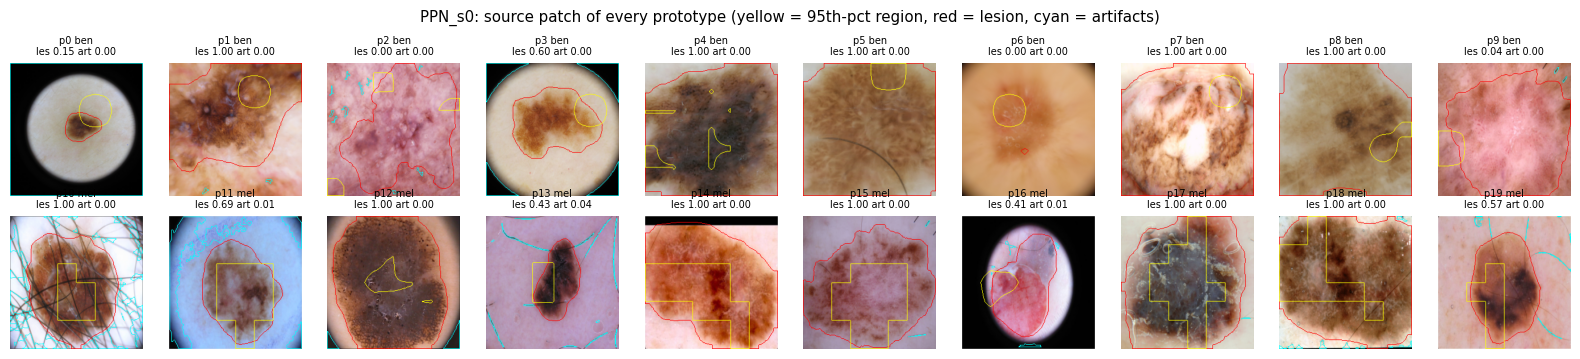

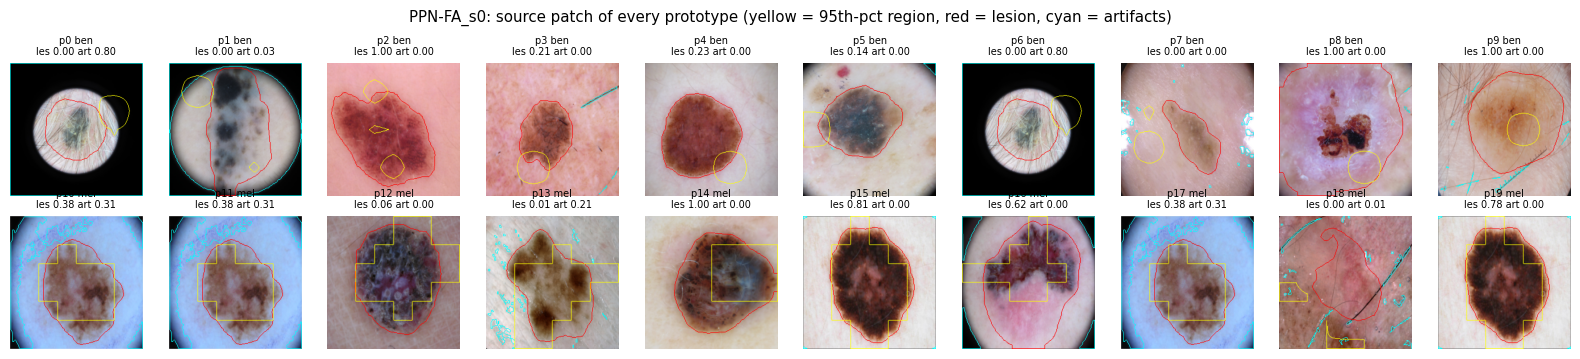

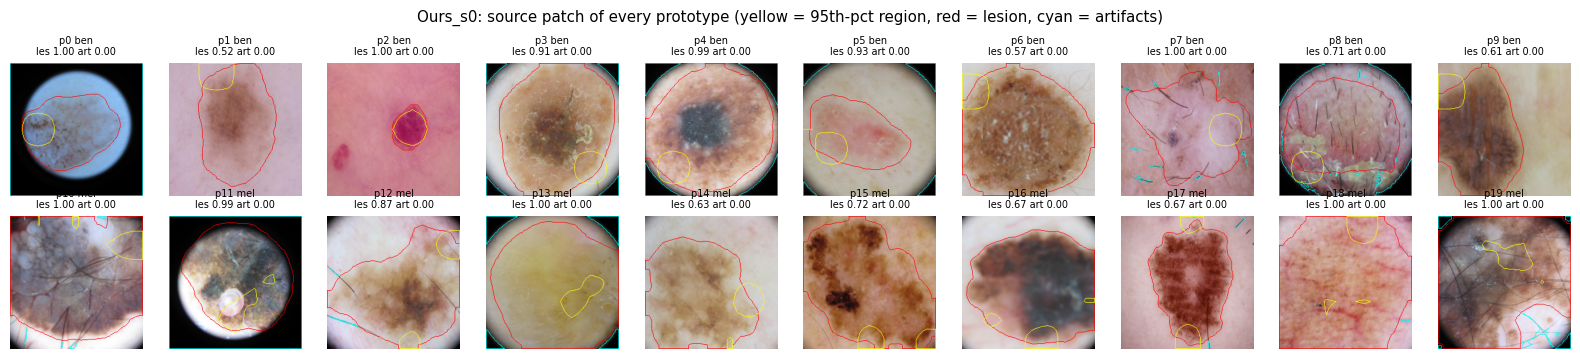

In [13]:
plt.rcParams.update({'font.size': 9, 'axes.titlesize': 9})
inv = lambda a: np.asarray(a)
def overlay(img224, heat, alpha=0.45):
    h = (heat - heat.min()) / (heat.max() - heat.min() + 1e-9)
    c = cv2.applyColorMap((h * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return (img224 * (1 - alpha) + c * alpha).astype(np.uint8)
def up(m7): return cv2.resize(np.asarray(m7, np.float32), (224, 224), interpolation=cv2.INTER_LINEAR)
def img224(a): return cv2.resize(np.asarray(a), (224, 224), interpolation=cv2.INTER_AREA)
def contour(img, mask, col):
    cs, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    out = img.copy(); cv2.drawContours(out, cs, -1, col, 1); return out

# (a) prototype galleries: where each prototype comes from (its source training patch)
for run in [r for r in ('PPN_s0', 'PPN-FA_s0', 'Ours_s0') if r in PRED]:
    p = PRED[run]['push']; model = MODELS[run]
    fig, ax = plt.subplots(2, 10, figsize=(16, 3.6))
    for a, (_, r) in zip(ax.flat, p.iterrows()):
        i = int(r.img); im = img224(IM[i]); m = np.array(MS[i])
        o = ek.forward(model, IM, MS, np.array([i]), dev, keep_maps=True)
        hm = up(o['sim'][0, int(r.proto)])
        hot = hm >= np.quantile(hm, 0.95)
        L224 = cv2.resize(((m & ap.BIT_L) > 0).astype(np.uint8), (224, 224), interpolation=cv2.INTER_NEAREST)
        A224 = cv2.resize(((m & ap.BIT_ART) > 0).astype(np.uint8), (224, 224), interpolation=cv2.INTER_NEAREST)
        vis = contour(contour(contour(im, L224, (255, 0, 0)), A224, (0, 255, 255)), hot, (255, 255, 0))
        a.imshow(vis); a.axis('off')
        a.set_title(f"p{int(r.proto)} {'mel' if r.cls == 1 else 'ben'}\nles {r.les_frac:.2f} art {r.art_frac:.2f}", fontsize=7)
    fig.suptitle(f'{run}: source patch of every prototype (yellow = 95th-pct region, red = lesion, cyan = artifacts)')
    plt.tight_layout(); plt.savefig(f'{FIG}/prototypes_{run}.png', dpi=200); plt.savefig(f'{FIG}/prototypes_{run}.pdf'); plt.show()

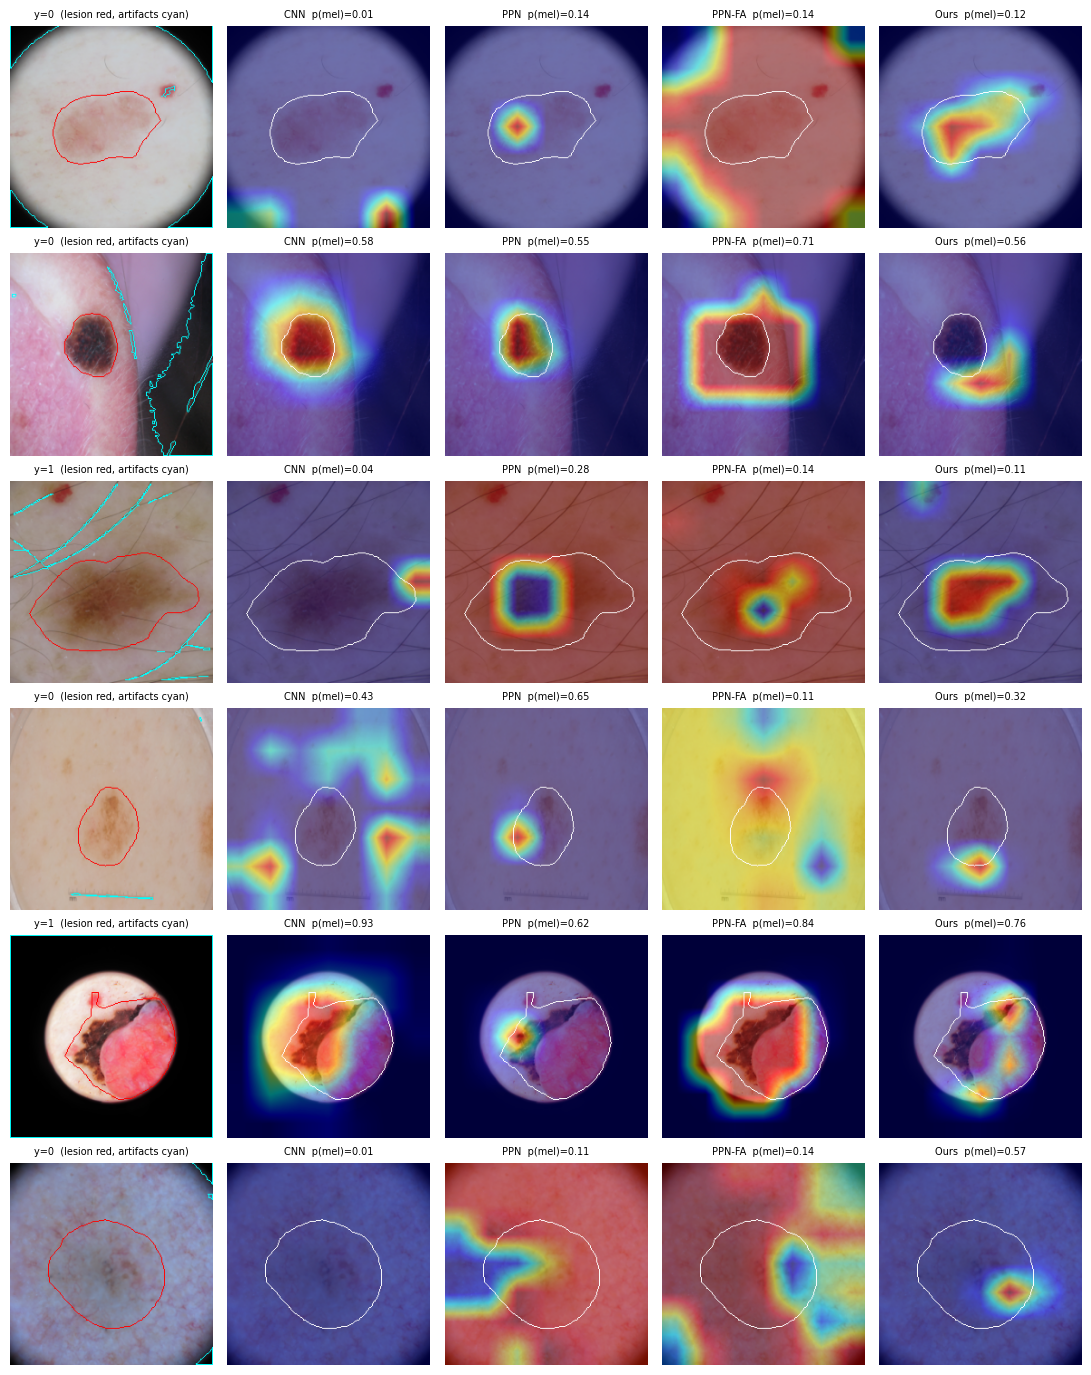

In [14]:
# (b) explanation maps on test images that contain artifacts: CNN Grad-CAM vs prototype models (top-1 prototype)
show_runs = [r for r in ('CNN_s0', 'PPN_s0', 'PPN-FA_s0', 'Ours_s0') if r in PRED]
tv = meta.iloc[IDX['test']]
cand = np.where((tv.art_DC.values | tv.art_TS.values) & tv.lesion_valid.values.astype(bool))[0]
pick = np.random.RandomState(3).choice(cand, min(6, len(cand)), replace=False)
fig, ax = plt.subplots(len(pick), 1 + len(show_runs), figsize=(2.2 * (1 + len(show_runs)), 2.3 * len(pick)))
ax = np.array(ax).reshape(len(pick), -1)
for rr, k in enumerate(pick):
    g = IDX['test'][k]; im = img224(IM[g]); m = np.array(MS[g])
    L224 = cv2.resize(((m & ap.BIT_L) > 0).astype(np.uint8), (224, 224), interpolation=cv2.INTER_NEAREST)
    A224 = cv2.resize(((m & ap.BIT_ART) > 0).astype(np.uint8), (224, 224), interpolation=cv2.INTER_NEAREST)
    ax[rr, 0].imshow(contour(contour(im, L224, (255, 0, 0)), A224, (0, 255, 255))); ax[rr, 0].set_title(f'y={y[g]}  (lesion red, artifacts cyan)', fontsize=7)
    for cc, run in enumerate(show_runs, 1):
        R = PRED[run]; v = 'sgd' if R['kind'] == 'cnn' else 'cvx'
        hm = up(CAM[run]['test'][k]) if R['kind'] == 'cnn' else up(R['test']['sim'][k, int(np.argmax(R['test']['act'][k]))])
        ax[rr, cc].imshow(contour(overlay(im, hm), L224, (255, 255, 255)))
        ax[rr, cc].set_title(f"{cfg_of(run)}  p(mel)={R['test'][f'prob_{v}'][k]:.2f}", fontsize=7)
for a in ax.flat: a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG}/explanations_examples.png', dpi=200); plt.savefig(f'{FIG}/explanations_examples.pdf'); plt.show()

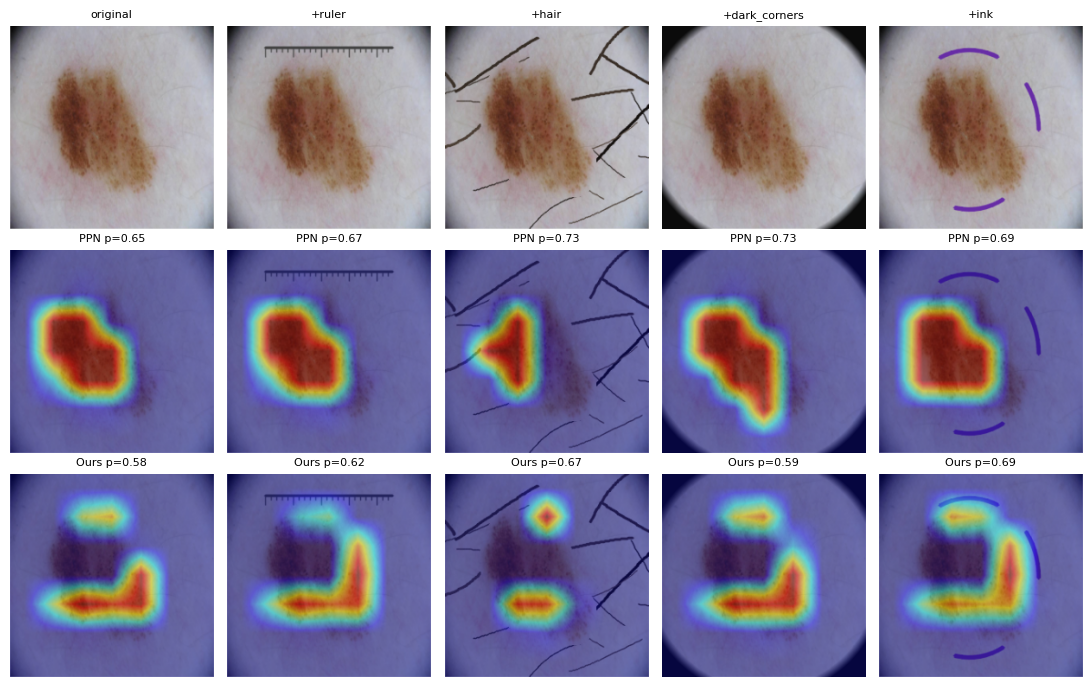

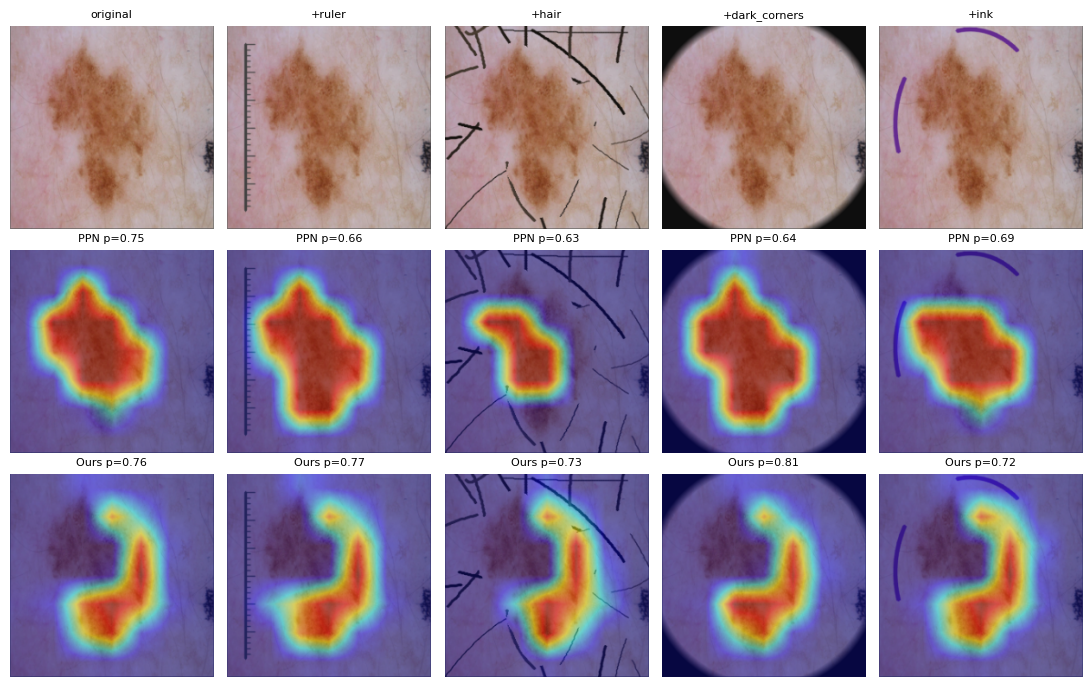

In [15]:
# (c) counterfactual examples: same lesion, added artifacts; maps of PPN vs Ours (top-1 prototype of the original)
kinds = ['add_ruler', 'add_hair', 'add_dark_corners', 'add_ink']
runs2 = [r for r in ('PPN_s0', 'Ours_s0') if r in PRED]
for e in range(2):
    fig, ax = plt.subplots(len(runs2) + 1, len(kinds) + 1, figsize=(2.2 * (len(kinds) + 1), 2.3 * (len(runs2) + 1)))
    g0 = CF_EXAMPLES[kinds[0]][0][e]
    for cc, kind in enumerate([None] + kinds):
        if kind is None: im256 = np.array(IM[g0]); title = 'original'
        else:
            gi, cfs, chs = CF_EXAMPLES[kind]
            w = np.where(gi == g0)[0]
            if len(w) == 0: ax[0, cc].axis('off'); continue
            im256 = cfs[w[0]]; title = kind.replace('add_', '+')
        ax[0, cc].imshow(img224(im256)); ax[0, cc].set_title(title, fontsize=8)
        for rr, run in enumerate(runs2, 1):
            R = PRED[run]; k0 = pos_in_test[g0]; top = int(np.argmax(R['test']['act'][k0]))
            o = ek.forward(MODELS[run], im256[None], np.array(MS[g0])[None], np.array([0]), dev, keep_maps=True)
            p1 = ek.probs_from_act(o['act'], R['W_cvx'])[0]
            ax[rr, cc].imshow(overlay(img224(im256), up(o['sim'][0, top])))
            ax[rr, cc].set_title(f'{cfg_of(run)} p={p1:.2f}', fontsize=8)
    for a in ax.flat: a.axis('off')
    plt.tight_layout(); plt.savefig(f'{FIG}/counterfactual_example_{e}.png', dpi=200); plt.savefig(f'{FIG}/counterfactual_example_{e}.pdf'); plt.show()

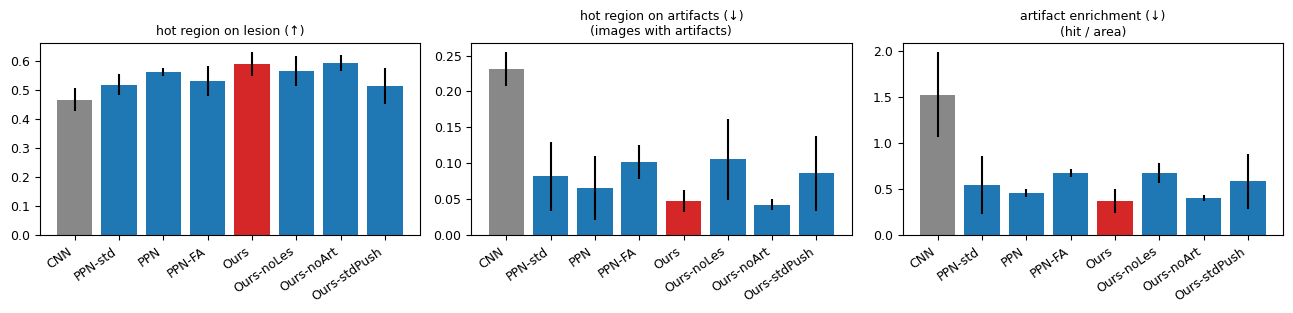

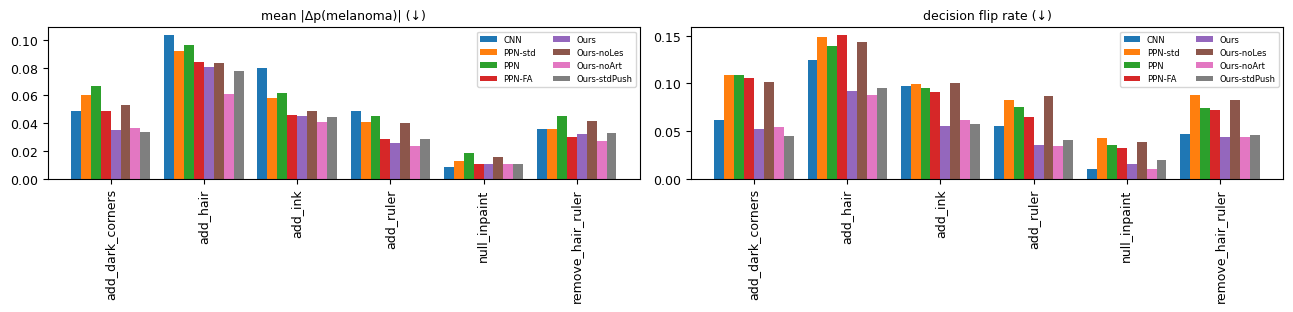

In [16]:
# (d) summary bar charts
tab = ATTR['test'][0]
cfgs = [c for c in CONFIG_ORDER if c in tab.config.values]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, col, ttl in zip(ax, ['hit_lesion', 'hit_artifact|art_present', 'enrichment_artifact'],
                       ['hot region on lesion (↑)', 'hot region on artifacts (↓)\n(images with artifacts)', 'artifact enrichment (↓)\n(hit / area)']):
    m = tab.groupby('config')[col].mean().reindex(cfgs); s = tab.groupby('config')[col].std().reindex(cfgs)
    a.bar(range(len(cfgs)), m.values, yerr=s.values, color=['#888' if c == 'CNN' else ('#d62728' if c == 'Ours' else '#1f77b4') for c in cfgs])
    a.set_xticks(range(len(cfgs))); a.set_xticklabels(cfgs, rotation=35, ha='right'); a.set_title(ttl)
plt.tight_layout(); plt.savefig(f'{FIG}/attribution_bars.png', dpi=200); plt.savefig(f'{FIG}/attribution_bars.pdf'); plt.show()
pr = pd.read_csv(f'{EV}/counterfactual_per_run.csv')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
for a, col, ttl in zip(ax, ['abs_dp', 'flip'], ['mean |Δp(melanoma)| (↓)', 'decision flip rate (↓)']):
    piv = pr.groupby(['intervention', 'config'])[col].mean().unstack().reindex(columns=[c for c in CONFIG_ORDER if c in pr.config.values])
    piv.plot.bar(ax=a, width=0.85); a.set_title(ttl); a.set_xlabel(''); a.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.savefig(f'{FIG}/counterfactual_bars.png', dpi=200); plt.savefig(f'{FIG}/counterfactual_bars.pdf'); plt.show()

## 6. Save LaTeX tables and summary

In [17]:
def to_tex(df, path, caption):
    open(path, 'w').write(df.to_latex(index=False, escape=True, caption=caption))
to_tex(CLS_AGG, f'{EV}/tab_classification.tex', 'Classification (mean ± std over 3 seeds).')
to_tex(DEL, f'{EV}/tab_auc_delong.tex', 'Seed-ensemble AUC with 95% bootstrap CI and paired DeLong tests vs. Ours.')
to_tex(CF_AGG, f'{EV}/tab_counterfactual.tex', 'Counterfactual interventions (mean ± std over seeds).')
to_tex(CFT, f'{EV}/tab_counterfactual_tests.tex', 'Paired Wilcoxon tests (per-image, seed-averaged).')
for sname, (tab, _) in ATTR.items():
    to_tex(tab, f'{EV}/tab_attribution_{sname}.tex', f'Attribution on {sname} (per run).')
summary = dict(n_runs=len(RUNS), runs=list(RUNS), minutes=round((time.time() - T0) / 60, 1),
               thresholds={r: dict(sgd=PRED[r]['thr_sgd'], cvx=PRED[r]['thr_cvx']) for r in PRED},
               cvx_loss={r: PRED[r].get('cvx_loss') for r in PRED})
json.dump(summary, open(f'{EV}/summary.json', 'w'), indent=1)
os.system(f'cd /kaggle/working && zip -qr eval.zip eval && ls -la eval eval/fig && du -sh eval eval.zip')
print('NB02 finished in', summary['minutes'], 'min')

eval:
total 10664
drwxr-xr-x 3 root root     4096 Oct 18 11:23 .
drwxr-xr-x 4 root root     4096 Oct 18 11:23 ..
-rw-r--r-- 1 root root     1534 Oct 18 11:12 attribution_Derm7pt-derm_mean_std.csv
-rw-r--r-- 1 root root     4173 Oct 18 11:12 attribution_Derm7pt-derm_per_run.csv
-rw-r--r-- 1 root root     1554 Oct 18 11:12 attribution_test_mean_std.csv
-rw-r--r-- 1 root root     4342 Oct 18 11:12 attribution_test_per_run.csv
-rw-r--r-- 1 root root     4651 Oct 18 11:11 auc_ensemble_delong.csv
-rw-r--r-- 1 root root    11873 Oct 18 11:09 classification_mean_std.csv
-rw-r--r-- 1 root root    55383 Oct 18 11:09 classification_per_run.csv
-rw-r--r-- 1 root root     9789 Oct 18 11:22 counterfactual_mean_std.csv
-rw-r--r-- 1 root root 10687129 Oct 18 11:22 counterfactual_per_image.csv.gz
-rw-r--r-- 1 root root    22443 Oct 18 11:22 counterfactual_per_run.csv
-rw-r--r-- 1 root root     4333 Oct 18 11:22 counterfactual_tests.csv
drwxr-xr-x 2 root root     4096 Oct 18 11:23 fig
-rw-r--r-- 1 root 